In [1]:
# ============================================================================
# IEEE ACCESS PAPER: HiENBERT - Hybrid Indic-English BERT for Multi-Task 
# Complaint Classification with Sentiment-Enhanced Severity Prediction
# 
# DATASET: complaints_hinglish.csv with columns:
#   - Sy_No, Complaint_Title, Text_en, Text_hi, Text_hinglish
#   - primary_category, secondary_category, Severity, Model_Name
# ============================================================================
# CELL 1: IMPORTS AND SYSTEM SETUP
# ============================================================================

import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pickle
import json
import random
from datetime import datetime
import time

# PyTorch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.cuda.amp import GradScaler, autocast

# Transformers
from transformers import (
    AutoTokenizer, 
    AutoModel,
    get_cosine_schedule_with_warmup
)

# Scikit-learn
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score,
    classification_report, 
    confusion_matrix,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef
)
from sklearn.manifold import TSNE

# SHAP for Explainable AI
import shap

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = True

set_seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n{'='*80}")
print(f"SYSTEM INFORMATION")
print(f"{'='*80}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    torch.backends.cudnn.benchmark = True
print(f"Using device: {device}")
print(f"{'='*80}\n")


SYSTEM INFORMATION
PyTorch version: 2.6.0+cu126
CUDA available: True
CUDA device: NVIDIA GeForce RTX 3070
CUDA memory: 8.59 GB
Using device: cuda



In [ ]:
# ============================================================================
# CELL 2: CONFIGURATION
# ============================================================================

import os
import torch


class Config:
    """Configuration settings for HiENBERT training"""

    # =========================================================================
    # BASE MODEL
    # =========================================================================

    BASE_MODEL = 'indicbert'
    # Options: 'indicbert', 'xlm-roberta'

    INDICBERT_PATH = "ai4bharat/indic-bert"
    XLMBERT_PATH = "xlm-roberta-base"

    # =========================================================================
    # PROJECT ROOT DIRECTORY
    # =========================================================================

    PROJECT_DIR = os.getcwd()

    # =========================================================================
    # INPUT DATASET DIRECTORY - Using Synthetic_Dataset
    # =========================================================================
    
    DATA_DIR = os.path.join(
        PROJECT_DIR,
        "Common_Dataset"
    )
    
    TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
    DEV_PATH = os.path.join(DATA_DIR, "dev.csv")
    TEST_PATH = os.path.join(DATA_DIR, "test.csv")
    
    # =========================================================================
    # OUTPUT DIRECTORY
    # =========================================================================
    
    BASE_DIR = os.path.join(
        PROJECT_DIR,
        "hienbert_results_common_dataset_indic"
    )
    
    # =========================================================================
    # OUTPUT SUBDIRECTORIES
    # =========================================================================
    
    MODEL_DIR = os.path.join(BASE_DIR, "models")
    VISUALIZATION_DIR = os.path.join(BASE_DIR, "visualizations")
    LOG_DIR = os.path.join(BASE_DIR, "logs")
    RESULTS_DIR = os.path.join(BASE_DIR, "results")
    CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints")
    PREDICTION_DIR = os.path.join(BASE_DIR, "predictions")
    EMBEDDING_DIR = os.path.join(BASE_DIR, "embeddings")
    SHAP_DIR = os.path.join(BASE_DIR, "shap_explanations")

    # =========================================================================
    # TRAINING PARAMETERS
    # =========================================================================

    MAX_LENGTH = 128
    BATCH_SIZE = 32
    EPOCHS = 15
    LEARNING_RATE = 2e-5
    DROPOUT = 0.3
    WEIGHT_DECAY = 0.01
    GRADIENT_ACCUMULATION_STEPS = 1
    WARMUP_RATIO = 0.1

    # =========================================================================
    # MIXED PRECISION
    # =========================================================================

    USE_AMP = True

    # =========================================================================
    # IMBALANCE HANDLING - Disabled for balanced dataset
    # =========================================================================

    USE_CLASS_WEIGHTS = False
    USE_FOCAL_LOSS = False
    USE_WEIGHTED_SAMPLER = False

    # =========================================================================
    # SEVERITY ENHANCEMENT
    # =========================================================================

    ENHANCE_SEVERITY = False
    SENTIMENT_THRESHOLD = 0.5

    # =========================================================================
    # DEVICE
    # =========================================================================

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # =========================================================================
    # RANDOM SEED
    # =========================================================================

    SEED = 42

    # =========================================================================
    # HUGGING FACE TOKEN
    # =========================================================================

    HF_TOKEN = os.getenv("HF_TOKEN")  # Replace with your token

    # =========================================================================
    # CREATE ALL DIRECTORIES
    # =========================================================================

    for dir_path in [
        BASE_DIR, MODEL_DIR, VISUALIZATION_DIR, LOG_DIR,
        RESULTS_DIR, CHECKPOINT_DIR, PREDICTION_DIR, 
        EMBEDDING_DIR, SHAP_DIR
    ]:
        os.makedirs(dir_path, exist_ok=True)


# ============================================================================
# GET MODEL PATH
# ============================================================================

def get_model_path():
    if Config.BASE_MODEL == 'indicbert':
        return Config.INDICBERT_PATH
    elif Config.BASE_MODEL == 'xlm-roberta':
        return Config.XLMBERT_PATH
    else:
        raise ValueError(f"Unsupported base model: {Config.BASE_MODEL}")


# ============================================================================
# CONFIGURATION SUMMARY
# ============================================================================

print("=" * 80)
print("HiENBERT CONFIGURATION")
print("=" * 80)

print("\n[MODEL]")
print(f"Base Model        : {Config.BASE_MODEL}")
print(f"Model Path        : {get_model_path()}")

print("\n[INPUT DATASET]")
print(f"Dataset Directory : {Config.DATA_DIR}")
print(f"Train Path        : {Config.TRAIN_PATH}")
print(f"Dev Path          : {Config.DEV_PATH}")
print(f"Test Path         : {Config.TEST_PATH}")

print("\n[OUTPUT]")
print(f"Base Output       : {Config.BASE_DIR}")

print("\n[TRAINING]")
print(f"Max Length        : {Config.MAX_LENGTH}")
print(f"Batch Size        : {Config.BATCH_SIZE}")
print(f"Epochs            : {Config.EPOCHS}")
print(f"Learning Rate     : {Config.LEARNING_RATE}")
print(f"Dropout           : {Config.DROPOUT}")

print("\n[DEVICE]")
print(f"Device            : {Config.DEVICE}")
if torch.cuda.is_available():
    print(f"GPU               : {torch.cuda.get_device_name(0)}")
else:
    print("GPU               : Not available")

print("\n[DATASET CHECK]")
print(f"Train exists      : {os.path.isfile(Config.TRAIN_PATH)}")
print(f"Dev exists        : {os.path.isfile(Config.DEV_PATH)}")
print(f"Test exists       : {os.path.isfile(Config.TEST_PATH)}")

print("\n" + "=" * 80)

HiENBERT CONFIGURATION

[MODEL]
Base Model        : indicbert
Model Path        : ai4bharat/indic-bert

[INPUT DATASET]
Dataset Directory : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\Common_Dataset
Train Path        : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\Common_Dataset\train.csv
Dev Path          : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\Common_Dataset\dev.csv
Test Path         : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\Common_Dataset\test.csv

[OUTPUT]
Base Output       : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic

[TRAINING]
Max Length        : 128
Batch Size        : 32
Epochs            : 15
Learning Rate     : 2e-05
Dropout           : 0.3

[DEVICE]
Device            : cuda
GPU               : NVIDIA GeForce RTX 3070

[DATASET CHECK]
Train exists      : True
Dev exists        : True
Test exists       : True



In [3]:
# ============================================================================
# CELL 3: DATA LOADING WITH BALANCED DATASET ANALYSIS
# ============================================================================

class BalancedDataLoader:
    """Load and analyze balanced dataset with correct column names"""
    
    def __init__(self):
        self.train_df = None
        self.dev_df = None
        self.test_df = None
        
    def load_data(self):
        """Load train, dev, test datasets"""
        print("Loading datasets...")
        
        self.train_df = pd.read_csv(Config.TRAIN_PATH)
        self.dev_df = pd.read_csv(Config.DEV_PATH)
        self.test_df = pd.read_csv(Config.TEST_PATH)
        
        print(f"Train samples: {len(self.train_df)}")
        print(f"Dev samples: {len(self.dev_df)}")
        print(f"Test samples: {len(self.test_df)}")
        
        # Display column names
        print(f"\nColumns in dataset: {self.train_df.columns.tolist()}")
        
        return self.train_df, self.dev_df, self.test_df
    
    def analyze_distribution(self, df, label_col, title=""):
        """Analyze class distribution"""
        class_counts = df[label_col].value_counts()
        class_percentages = df[label_col].value_counts(normalize=True) * 100
        
        print(f"\n{'='*60}")
        print(f"Class Distribution Analysis - {title}")
        print(f"{'='*60}")
        
        for cls, count in class_counts.items():
            pct = class_percentages[cls]
            print(f"  {cls}: {count} samples ({pct:.2f}%)")
        
        max_count = class_counts.max()
        min_count = class_counts.min()
        imbalance_ratio = max_count / min_count if min_count > 0 else float('inf')
        
        print(f"\nBalance Metrics:")
        print(f"  Total classes: {len(class_counts)}")
        print(f"  Majority class size: {max_count}")
        print(f"  Minority class size: {min_count}")
        print(f"  Imbalance ratio: {imbalance_ratio:.2f}:1")
        
        if imbalance_ratio <= 1.5:
            print("  ✅ Dataset is well-balanced!")
        elif imbalance_ratio <= 3.0:
            print("  ⚠️ Dataset has moderate imbalance")
        else:
            print("  ❌ Dataset has significant imbalance")
        
        return class_counts, class_percentages
    
    def analyze_all(self):
        """Complete analysis of balanced dataset"""
        self.load_data()
        
        print("\n" + "="*80)
        print("BALANCED DATASET ANALYSIS")
        print("="*80)
        
        # Analyze all label columns
        self.analyze_distribution(self.train_df, 'primary_category', 'Primary Categories (Train)')
        self.analyze_distribution(self.train_df, 'secondary_category', 'Secondary Categories (Train)')
        self.analyze_distribution(self.train_df, 'Severity', 'Severity (Train)')
        
        return self.train_df, self.dev_df, self.test_df

# Initialize and analyze
data_loader = BalancedDataLoader()
train_df, dev_df, test_df = data_loader.load_data()

# Analyze balanced distribution
data_loader.analyze_all()

print(f"\n✅ Balanced data loaded and analyzed successfully")

Loading datasets...
Train samples: 14165
Dev samples: 3035
Test samples: 3036

Columns in dataset: ['Sy_No', 'Complaint_Title', 'Text_en', 'Text_hi', 'Text_hinglish', 'primary_category', 'secondary_category', 'Severity', 'Model_Name']
Loading datasets...
Train samples: 14165
Dev samples: 3035
Test samples: 3036

Columns in dataset: ['Sy_No', 'Complaint_Title', 'Text_en', 'Text_hi', 'Text_hinglish', 'primary_category', 'secondary_category', 'Severity', 'Model_Name']

BALANCED DATASET ANALYSIS

Class Distribution Analysis - Primary Categories (Train)
  Road & Transportation: 2710 samples (19.13%)
  Waste Management: 2075 samples (14.65%)
  Electricity: 1908 samples (13.47%)
  Others: 1616 samples (11.41%)
  Water Leakage: 1573 samples (11.10%)
  Health & Sanitation: 1470 samples (10.38%)
  Public Safety: 1408 samples (9.94%)
  Encroachment & Illegal Construction: 1405 samples (9.92%)

Balance Metrics:
  Total classes: 8
  Majority class size: 2710
  Minority class size: 1405
  Imbalance 

In [4]:
# ============================================================================
# CELL 4: DATA PREPROCESSING - WITHOUT SENTIMENT ENHANCEMENT
# ============================================================================

class DataPreprocessor:
    """Data preprocessing - Uses original severity labels, no sentiment enhancement"""
    
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        
        # Column name mapping
        self.column_mapping = {
            'primary_category': 'category_primary',
            'secondary_category': 'category_secondary',
            'Severity': 'severity',
            'Complaint_Title': 'complaint_title',
            'Text_en': 'text_en',
            'Text_hi': 'Hindi',
            'Text_hinglish': 'Hinglish',
            'Sy_No': 'sy_no'
        }
        
    def rename_columns(self, df):
        """Rename columns to match expected names"""
        rename_dict = {k: v for k, v in self.column_mapping.items() if k in df.columns}
        if rename_dict:
            df = df.rename(columns=rename_dict)
        return df
    
    def preprocess_text(self, df):
        """Combine text fields and handle missing values"""
    
        # Rename columns first
        df = self.rename_columns(df)
    
        # Fill NaN values
        for col in [
            'complaint_title',
            'text_en',
            'Hindi',
            'Hinglish'
        ]:
            if col in df.columns:
                df[col] = df[col].fillna('').astype(str)
    
        # Build combined text column row-wise
        text_columns = []
    
        if 'complaint_title' in df.columns:
            text_columns.append('complaint_title')
    
        if 'text_en' in df.columns:
            text_columns.append('text_en')
    
        if 'Hindi' in df.columns:
            text_columns.append('Hindi')
    
        if 'Hinglish' in df.columns:
            text_columns.append('Hinglish')
    
        if len(text_columns) > 0:
            df["text"] = (
                df[text_columns]
                .agg(" ".join, axis=1)
                .str.replace(r"\s+", " ", regex=True)
                .str.strip()
            )
        else:
            raise ValueError("No text columns found!")
    
        df = df.dropna(
            subset=[
                "category_primary",
                "category_secondary",
                "severity"
            ]
        )
    
        return df.reset_index(drop=True)
    def prepare_labels(self, train_df, dev_df, test_df):
        """Encode all labels"""
        print("\nPreparing labels...")
        
        # Fit encoders on training data
        self.le_primary.fit(train_df['category_primary'])
        self.le_subcat.fit(train_df['category_secondary'])
        self.le_severity.fit(train_df['severity'])  # Use original severity directly
        
        print(f"Primary categories: {len(self.le_primary.classes_)}")
        print(f"Subcategories: {len(self.le_subcat.classes_)}")
        print(f"Severity levels: {len(self.le_severity.classes_)}")
        
        # Transform all datasets
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["severity"])
            # Add dummy sentiment score (will be 0 for all samples)
            df["sentiment_score"] = 0.0
        
        return train_df, dev_df, test_df
    
    def process_data(self, train_df, dev_df, test_df):
        """Complete data processing pipeline"""
        # Preprocess text
        print("\nPreprocessing text...")
        train_df = self.preprocess_text(train_df)
        dev_df = self.preprocess_text(dev_df)
        test_df = self.preprocess_text(test_df)
        
        # Display severity distribution
        print(f"\nSeverity values in training data: {train_df['severity'].unique()}")
        print(f"Severity value counts:\n{train_df['severity'].value_counts()}")
        
        # Display balanced distribution
        severity_counts = train_df['severity'].value_counts()
        total = len(train_df)
        print("\nOriginal Severity Distribution (Training):")
        for severity in ['Low', 'Medium', 'High']:
            count = severity_counts.get(severity, 0)
            pct = (count / total) * 100
            print(f"  {severity}: {count} ({pct:.1f}%)")
        
        # Prepare labels (no sentiment enhancement)
        train_df, dev_df, test_df = self.prepare_labels(train_df, dev_df, test_df)
        
        print(f"\nFinal datasets:")
        print(f"  Training: {len(train_df)} samples")
        print(f"  Validation: {len(dev_df)} samples")
        print(f"  Test: {len(test_df)} samples")
        
        return train_df, dev_df, test_df

# Process data
preprocessor = DataPreprocessor()
train_df, dev_df, test_df = preprocessor.process_data(train_df, dev_df, test_df)

print("\n✅ Data preprocessing completed successfully")
print("✅ Using original severity labels (No sentiment enhancement)")


Preprocessing text...

Severity values in training data: ['Medium' 'Low' 'High']
Severity value counts:
severity
Low       5898
Medium    4290
High      3977
Name: count, dtype: int64

Original Severity Distribution (Training):
  Low: 5898 (41.6%)
  Medium: 4290 (30.3%)
  High: 3977 (28.1%)

Preparing labels...
Primary categories: 8
Subcategories: 24
Severity levels: 3

Final datasets:
  Training: 14165 samples
  Validation: 3035 samples
  Test: 3036 samples

✅ Data preprocessing completed successfully
✅ Using original severity labels (No sentiment enhancement)


In [5]:
# ============================================================================
# CELL 5: DATASET CLASS
# ============================================================================

class ComplaintDataset(Dataset):
    """Custom dataset for complaint classification"""
    
    def __init__(self, df, tokenizer, max_length=128, use_sentiment=False):
        self.texts = df["text"].astype(str).tolist()
        self.primary = df["primary_label"].tolist()
        self.subcat = df["subcat_label"].tolist()
        self.severity = df["severity_label"].tolist()
        self.sentiment = [0.0] * len(df)  # Dummy sentiment (not used)
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.use_sentiment = use_sentiment
        
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        text = self.texts[idx]
        
        enc = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        
        features = {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": torch.tensor(self.primary[idx], dtype=torch.long),
            "subcat": torch.tensor(self.subcat[idx], dtype=torch.long),
            "severity": torch.tensor(self.severity[idx], dtype=torch.long),
            "sentiment": torch.tensor(self.sentiment[idx], dtype=torch.float)  # Dummy
        }
        
        return features


def create_dataloaders(train_df, dev_df, test_df, tokenizer):
    """Create dataloaders"""
    print("\nCreating datasets and dataloaders...")
    
    # Create datasets (use_sentiment=False)
    train_dataset = ComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH, use_sentiment=False)
    dev_dataset = ComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH, use_sentiment=False)
    test_dataset = ComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH, use_sentiment=False)
    
    train_loader = DataLoader(
        train_dataset, 
        batch_size=Config.BATCH_SIZE, 
        shuffle=True,
        num_workers=0,
        pin_memory=True,
        drop_last=False
    )
    
    dev_loader = DataLoader(
        dev_dataset, 
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False, 
        num_workers=0,
        pin_memory=True
    )
    
    test_loader = DataLoader(
        test_dataset, 
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False, 
        num_workers=0,
        pin_memory=True
    )
    
    print(f"Train batches: {len(train_loader)}")
    print(f"Dev batches: {len(dev_loader)}")
    print(f"Test batches: {len(test_loader)}")
    
    return train_loader, dev_loader, test_loader

print("✅ Dataset class defined successfully")

✅ Dataset class defined successfully


In [6]:
# ============================================================================
# CELL 6: LOSS FUNCTIONS
# ============================================================================

class MultiTaskLoss(nn.Module):
    """Multi-task loss using standard cross-entropy"""
    
    def __init__(self):
        super().__init__()
        
        self.primary_loss = nn.CrossEntropyLoss()
        self.subcat_loss = nn.CrossEntropyLoss()
        self.severity_loss = nn.CrossEntropyLoss()
        
        self.primary_weight = 1.0
        self.subcat_weight = 1.0
        self.severity_weight = 0.5  # Lower weight for severity
        
    def forward(self, p1, p2, p3, y1, y2, y3):
        loss1 = self.primary_loss(p1, y1)
        loss2 = self.subcat_loss(p2, y2)
        loss3 = self.severity_loss(p3, y3)
        
        total_loss = (self.primary_weight * loss1 + 
                      self.subcat_weight * loss2 + 
                      self.severity_weight * loss3)
        
        return total_loss, {
            'primary': loss1.item(),
            'subcat': loss2.item(),
            'severity': loss3.item(),
            'total': total_loss.item()
        }

# Initialize loss function
criterion = MultiTaskLoss()

print(f"✅ Loss function initialized using CrossEntropyLoss")
print(f"  No sentiment enhancement - using original severity labels")

✅ Loss function initialized using CrossEntropyLoss
  No sentiment enhancement - using original severity labels


In [7]:
# ============================================================================
# CELL 7: LOAD BASE MODEL
# ============================================================================

def load_base_model():
    """Load base model and tokenizer based on configuration"""
    model_path = get_model_path()
    print(f"Loading base model: {model_path}")
    print(f"Model type: {Config.BASE_MODEL}")
    
    # Load tokenizer
    if Config.BASE_MODEL == 'indicbert':
        tokenizer = AutoTokenizer.from_pretrained(
            model_path,
            token=Config.HF_TOKEN,
            use_fast=False
        )
    else:
        tokenizer = AutoTokenizer.from_pretrained(
            model_path,
            token=Config.HF_TOKEN
        )
    
    # Add padding token if not present
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    
    # Load base model
    base_model = AutoModel.from_pretrained(
        model_path,
        token=Config.HF_TOKEN
    )
    
    print(f"Vocabulary size: {tokenizer.vocab_size}")
    print(f"Hidden size: {base_model.config.hidden_size}")
    
    return base_model, tokenizer

# Load model and tokenizer
base_model, tokenizer = load_base_model()

# Move model to device
base_model = base_model.to(Config.DEVICE)

print(f"\n✅ {Config.BASE_MODEL.upper()} loaded successfully on {Config.DEVICE}")

Loading base model: ai4bharat/indic-bert
Model type: indicbert


Loading weights: 100%|██████████| 25/25 [00:00<?, ?it/s]
[transformers] AlbertModel LOAD REPORT from: ai4bharat/indic-bert
Key                              | Status     |  | 
---------------------------------+------------+--+-
predictions.dense.weight         | UNEXPECTED |  | 
predictions.LayerNorm.weight     | UNEXPECTED |  | 
predictions.bias                 | UNEXPECTED |  | 
predictions.dense.bias           | UNEXPECTED |  | 
predictions.decoder.weight       | UNEXPECTED |  | 
sop_classifier.classifier.weight | UNEXPECTED |  | 
predictions.LayerNorm.bias       | UNEXPECTED |  | 
sop_classifier.classifier.bias   | UNEXPECTED |  | 
predictions.decoder.bias         | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Vocabulary size: 200000
Hidden size: 768

✅ INDICBERT loaded successfully on cuda


In [8]:
# ============================================================================
# CELL 8: HIENBERT MODEL DEFINITION - WITHOUT SENTIMENT
# ============================================================================

class HiEnBERTModel(nn.Module):
    """
    HiENBERT: Hybrid Indic-English BERT for Multi-Task Classification
    WITHOUT sentiment enhancement (uses original severity)
    """
    
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        
        self.shared_layer = nn.Sequential(
            nn.Linear(hidden_size, hidden_size),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size, n_severity)  # No sentiment input
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
        
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        
        x = self.shared_layer(cls_embedding)
        x = self.dropout(x)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)  # Direct severity prediction
        
        return primary_logits, subcat_logits, severity_logits
    
    def get_embeddings(self, input_ids, attention_mask):
        with torch.no_grad():
            outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
            return outputs.last_hidden_state[:, 0, :]

# Create model
n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = HiEnBERTModel(
    base_model=base_model,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=Config.DROPOUT
).to(Config.DEVICE)

print(f"Model architecture:")
print(f"  Base Model: {Config.BASE_MODEL.upper()}")
print(f"  Hidden Size: {model.hidden_size}")
print(f"  Primary classes: {n_primary}")
print(f"  Subcategory classes: {n_subcat}")
print(f"  Severity classes: {n_severity}")
print(f"  Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"  Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
print(f"  Sentiment Enhancement: DISABLED")

print("\n✅ HiENBERT model created successfully")

Model architecture:
  Base Model: INDICBERT
  Hidden Size: 768
  Primary classes: 8
  Subcategory classes: 24
  Severity classes: 3
  Total parameters: 34,061,091
  Trainable parameters: 34,061,091
  Sentiment Enhancement: DISABLED

✅ HiENBERT model created successfully


In [9]:
# ============================================================================
# CELL 9: TRAINING FUNCTIONS
# ============================================================================

class EarlyStopping:
    """Early stopping with patience"""
    
    def __init__(self, patience=7, min_delta=0.001, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.best_epoch = 0
        
    def __call__(self, score, epoch):
        if self.best_score is None:
            self.best_score = score
            self.best_epoch = epoch
            return False
        
        if self.mode == 'max':
            improvement = score - self.best_score > self.min_delta
        else:
            improvement = self.best_score - score > self.min_delta
            
        if improvement:
            self.best_score = score
            self.best_epoch = epoch
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
                
        return self.early_stop


def train_epoch(model, dataloader, optimizer, scheduler, criterion, device, 
                gradient_accumulation_steps=1, scaler=None):
    """Train for one epoch"""
    model.train()
    total_loss = 0
    all_preds = []
    all_labels = []
    task_losses = {'primary': 0, 'subcat': 0, 'severity': 0, 'total': 0}
    
    progress_bar = tqdm(dataloader, desc='Training', leave=False)
    
    for batch_idx, batch in enumerate(progress_bar):
        input_ids = batch['input_ids'].to(device, non_blocking=True)
        attention_mask = batch['attention_mask'].to(device, non_blocking=True)
        y_primary = batch['primary'].to(device, non_blocking=True)
        y_subcat = batch['subcat'].to(device, non_blocking=True)
        y_severity = batch['severity'].to(device, non_blocking=True)
        sentiment = batch['sentiment'].to(device, non_blocking=True)
        
        if scaler is not None:
            with autocast():
                p1, p2, p3 = model(input_ids, attention_mask, sentiment)
                loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        else:
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        
        loss = loss / gradient_accumulation_steps
        if scaler is not None:
            scaler.scale(loss).backward()
        else:
            loss.backward()
        
        if (batch_idx + 1) % gradient_accumulation_steps == 0:
            if scaler is not None:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
        
        total_loss += loss.item() * gradient_accumulation_steps
        
        for key in task_losses:
            if key in loss_dict:
                task_losses[key] += loss_dict[key]
        
        preds = torch.argmax(p1, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_primary.cpu().numpy())
        
        progress_bar.set_postfix({
            'loss': f'{loss.item() * gradient_accumulation_steps:.4f}',
            'acc': f'{accuracy_score(all_labels[-batch["input_ids"].size(0):], preds.cpu().numpy()):.3f}'
        })
    
    avg_loss = total_loss / len(dataloader)
    accuracy = accuracy_score(all_labels, all_preds)
    balanced_acc = balanced_accuracy_score(all_labels, all_preds)
    
    for key in task_losses:
        task_losses[key] /= len(dataloader)
    
    return avg_loss, accuracy, balanced_acc, task_losses


def evaluate(model, dataloader, device, return_predictions=False):
    """Comprehensive evaluation"""
    model.eval()
    all_preds = []
    all_labels = []
    all_confidences = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            sentiment = batch['sentiment'].to(device, non_blocking=True)
            
            p1, _, _ = model(input_ids, attention_mask, sentiment)
            
            probs = torch.softmax(p1, dim=1)
            preds = torch.argmax(p1, dim=1)
            confidences = probs.max(dim=1)[0]
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['primary'].cpu().numpy())
            all_confidences.extend(confidences.cpu().numpy())
    
    accuracy = accuracy_score(all_labels, all_preds)
    balanced_acc = balanced_accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro')
    f1_weighted = f1_score(all_labels, all_preds, average='weighted')
    precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
    recall = recall_score(all_labels, all_preds, average='weighted', zero_division=0)
    cohen_kappa = cohen_kappa_score(all_labels, all_preds)
    mcc = matthews_corrcoef(all_labels, all_preds)
    
    metrics = {
        'accuracy': accuracy,
        'balanced_accuracy': balanced_acc,
        'f1_macro': f1_macro,
        'f1_weighted': f1_weighted,
        'precision': precision,
        'recall': recall,
        'cohen_kappa': cohen_kappa,
        'mcc': mcc,
        'confidences': np.array(all_confidences)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    else:
        return metrics

In [10]:
# ============================================================================
# CELL 10: CREATE DATALOADERS AND SETUP TRAINING
# ============================================================================

# Create dataloaders
train_loader, dev_loader, test_loader = create_dataloaders(
    train_df, dev_df, test_df, tokenizer
)

# Setup optimizer and scheduler
optimizer = AdamW(
    model.parameters(), 
    lr=Config.LEARNING_RATE, 
    weight_decay=Config.WEIGHT_DECAY,
    betas=(0.9, 0.999)
)

total_steps = len(train_loader) * Config.EPOCHS
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(Config.WARMUP_RATIO * total_steps),
    num_training_steps=total_steps
)

# Gradient scaler for mixed precision
scaler = GradScaler() if Config.USE_AMP and torch.cuda.is_available() else None

# Early stopping
early_stopping = EarlyStopping(patience=7, mode='max')

print(f"Training setup completed:")
print(f"  Total steps: {total_steps}")
print(f"  Warmup steps: {int(Config.WARMUP_RATIO * total_steps)}")
print(f"  Mixed precision: {scaler is not None}")
print(f"  Batch size: {Config.BATCH_SIZE}")
print(f"  Gradient accumulation: {Config.GRADIENT_ACCUMULATION_STEPS}")

print("\n✅ Training setup ready")


Creating datasets and dataloaders...
Train batches: 443
Dev batches: 48
Test batches: 48
Training setup completed:
  Total steps: 6645
  Warmup steps: 664
  Mixed precision: True
  Batch size: 32
  Gradient accumulation: 1

✅ Training setup ready


In [11]:
# ============================================================================
# CELL 11: TRAIN THE MODEL
# ============================================================================

# Training history
train_history = []
val_history = []
best_val_f1 = 0
best_val_balanced_acc = 0

print("\n" + "="*80)
print(f"Training HiENBERT with {Config.BASE_MODEL.upper()} Base")
print(f"Model: {get_model_path()}")
print("="*80 + "\n")

start_time = time.time()

for epoch in range(Config.EPOCHS):
    epoch_start = time.time()
    print(f"\nEpoch {epoch+1}/{Config.EPOCHS}")
    print("-"*50)
    
    # Training
    train_loss, train_acc, train_bal_acc, task_losses = train_epoch(
        model, train_loader, optimizer, scheduler, criterion, Config.DEVICE,
        Config.GRADIENT_ACCUMULATION_STEPS, scaler
    )
    
    # Validation
    val_metrics = evaluate(model, dev_loader, Config.DEVICE)
    val_acc = val_metrics['accuracy']
    val_bal_acc = val_metrics['balanced_accuracy']
    val_f1 = val_metrics['f1_weighted']
    
    epoch_time = time.time() - epoch_start
    
    # Track history
    train_history.append({
        'loss': train_loss,
        'acc': train_acc,
        'balanced_acc': train_bal_acc,
        'task_losses': task_losses,
        'lr': scheduler.get_last_lr()[0],
        'time': epoch_time
    })
    
    val_history.append({
        'val_acc': val_acc,
        'val_bal_acc': val_bal_acc,
        'val_f1': val_f1,
        'metrics': val_metrics,
        'time': epoch_time
    })
    
    # Print results
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Bal Acc: {train_bal_acc:.4f}")
    print(f"Val Acc: {val_acc:.4f} | Bal Acc: {val_bal_acc:.4f} | F1: {val_f1:.4f}")
    print(f"Task Losses: Primary={task_losses['primary']:.3f}, "
          f"Subcat={task_losses['subcat']:.3f}, "
          f"Severity={task_losses['severity']:.3f}")
    print(f"Epoch Time: {epoch_time:.1f}s")
    
    # Save best model (by F1)
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_val_balanced_acc = val_bal_acc
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': val_f1,
            'val_balanced_acc': val_bal_acc,
            'train_history': train_history,
            'val_history': val_history,
            'label_encoders': {
                'primary': preprocessor.le_primary,
                'subcat': preprocessor.le_subcat,
                'severity': preprocessor.le_severity
            },
            'config': {
                'base_model': Config.BASE_MODEL,
                'model_path': get_model_path()
            }
        }
        torch.save(checkpoint, f"{Config.MODEL_DIR}/best_hienbert_model.pt")
        print(f"✓ New best model saved! F1: {val_f1:.4f}, Bal Acc: {val_bal_acc:.4f}")
    
    # Early stopping
    if early_stopping(val_f1, epoch):
        print(f"Early stopping triggered after {epoch+1} epochs")
        break

total_time = time.time() - start_time
print(f"\n✅ Training completed in {total_time/60:.1f} minutes")


Training HiENBERT with INDICBERT Base
Model: ai4bharat/indic-bert


Epoch 1/15
--------------------------------------------------


Train Loss: 5.5837 | Train Acc: 0.2109 | Bal Acc: 0.1773
Val Acc: 0.4666 | Bal Acc: 0.4291 | F1: 0.3874
Task Losses: Primary=2.012, Subcat=3.042, Severity=1.060
Epoch Time: 74.2s
✓ New best model saved! F1: 0.3874, Bal Acc: 0.4291

Epoch 2/15
--------------------------------------------------


Train Loss: 3.7678 | Train Acc: 0.7771 | Bal Acc: 0.7626
Val Acc: 0.8662 | Bal Acc: 0.8616 | F1: 0.8647
Task Losses: Primary=1.033, Subcat=2.213, Severity=1.043
Epoch Time: 73.7s
✓ New best model saved! F1: 0.8647, Bal Acc: 0.8616

Epoch 3/15
--------------------------------------------------


Train Loss: 2.4157 | Train Acc: 0.8815 | Bal Acc: 0.8777
Val Acc: 0.8913 | Bal Acc: 0.8892 | F1: 0.8911
Task Losses: Primary=0.480, Subcat=1.412, Severity=1.047
Epoch Time: 73.9s
✓ New best model saved! F1: 0.8911, Bal Acc: 0.8892

Epoch 4/15
--------------------------------------------------


Train Loss: 1.8989 | Train Acc: 0.9132 | Bal Acc: 0.9119
Val Acc: 0.9025 | Bal Acc: 0.9015 | F1: 0.9020
Task Losses: Primary=0.339, Subcat=1.052, Severity=1.016
Epoch Time: 73.8s
✓ New best model saved! F1: 0.9020, Bal Acc: 0.9015

Epoch 5/15
--------------------------------------------------


Train Loss: 1.5589 | Train Acc: 0.9321 | Bal Acc: 0.9311
Val Acc: 0.9091 | Bal Acc: 0.9113 | F1: 0.9093
Task Losses: Primary=0.265, Subcat=0.816, Severity=0.955
Epoch Time: 73.8s
✓ New best model saved! F1: 0.9093, Bal Acc: 0.9113

Epoch 6/15
--------------------------------------------------


... (5 outputs left out)

Train Loss: 0.4944 | Train Acc: 0.9881 | Bal Acc: 0.9875
Val Acc: 0.9137 | Bal Acc: 0.9145 | F1: 0.9137
Task Losses: Primary=0.063, Subcat=0.229, Severity=0.405
Epoch Time: 74.5s
✓ New best model saved! F1: 0.9137, Bal Acc: 0.9145

Epoch 12/15
--------------------------------------------------


Train Loss: 0.4328 | Train Acc: 0.9910 | Bal Acc: 0.9902
Val Acc: 0.9127 | Bal Acc: 0.9139 | F1: 0.9128
Task Losses: Primary=0.055, Subcat=0.197, Severity=0.362
Epoch Time: 74.1s

Epoch 13/15
--------------------------------------------------


Train Loss: 0.3915 | Train Acc: 0.9934 | Bal Acc: 0.9930
Val Acc: 0.9133 | Bal Acc: 0.9144 | F1: 0.9135
Task Losses: Primary=0.047, Subcat=0.178, Severity=0.333
Epoch Time: 73.6s

Epoch 14/15
--------------------------------------------------


Train Loss: 0.3694 | Train Acc: 0.9929 | Bal Acc: 0.9926
Val Acc: 0.9127 | Bal Acc: 0.9137 | F1: 0.9128
Task Losses: Primary=0.045, Subcat=0.168, Severity=0.313
Epoch Time: 73.8s
Early stopping triggered after 14 epochs

✅ Training completed in 17.3 minutes


In [12]:
# ============================================================================
# CELL 12: FINAL TEST EVALUATION
# ============================================================================

print("\n" + "=" * 80)
print("Final Test Set Evaluation")
print("=" * 80)


# ============================================================================
# LOAD BEST MODEL CHECKPOINT
# ============================================================================

checkpoint_path = os.path.join(
    Config.MODEL_DIR,
    "best_hienbert_model.pt"
)

print(f"\nLoading best model from:")
print(checkpoint_path)

if not os.path.isfile(checkpoint_path):
    raise FileNotFoundError(
        f"Best model checkpoint not found:\n{checkpoint_path}"
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location=Config.DEVICE,
    weights_only=False
)

print("✓ Checkpoint loaded successfully")


# ============================================================================
# RESTORE BEST MODEL WEIGHTS
# ============================================================================

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(Config.DEVICE)
model.eval()

print("✓ Best model weights restored")


# ============================================================================
# DISPLAY BEST CHECKPOINT INFORMATION
# ============================================================================

if "epoch" in checkpoint:
    print(f"Best checkpoint epoch: {checkpoint['epoch'] + 1}")

if "val_f1" in checkpoint:
    print(f"Best validation F1: {checkpoint['val_f1']:.4f}")

if "val_balanced_acc" in checkpoint:
    print(
        f"Best validation Balanced Accuracy: "
        f"{checkpoint['val_balanced_acc']:.4f}"
    )


# ============================================================================
# FINAL TEST SET EVALUATION
# ============================================================================

print("\nRunning evaluation on test set...")

test_metrics, test_preds, test_labels = evaluate(
    model,
    test_loader,
    Config.DEVICE,
    return_predictions=True
)


# ============================================================================
# DISPLAY TEST RESULTS
# ============================================================================

print("\n" + "=" * 80)
print("TEST RESULTS")
print("=" * 80)

print(f"  Accuracy          : {test_metrics['accuracy']:.4f}")
print(f"  Balanced Accuracy : {test_metrics['balanced_accuracy']:.4f}")
print(f"  F1-Macro          : {test_metrics['f1_macro']:.4f}")
print(f"  F1-Weighted       : {test_metrics['f1_weighted']:.4f}")
print(f"  Precision         : {test_metrics['precision']:.4f}")
print(f"  Recall            : {test_metrics['recall']:.4f}")
print(f"  Cohen's Kappa     : {test_metrics['cohen_kappa']:.4f}")
print(f"  Matthews CC       : {test_metrics['mcc']:.4f}")


# ============================================================================
# SAVE FINAL MODEL
# ============================================================================

final_model_path = os.path.join(
    Config.MODEL_DIR,
    "hienbert_model.pt"
)

torch.save(
    model.state_dict(),
    final_model_path
)

print(f"\n✓ Final model saved to:")
print(final_model_path)


# ============================================================================
# SAVE LABEL ENCODERS
# ============================================================================

primary_encoder_path = os.path.join(Config.MODEL_DIR, "le_primary.pkl")
subcat_encoder_path = os.path.join(Config.MODEL_DIR, "le_subcat.pkl")
severity_encoder_path = os.path.join(Config.MODEL_DIR, "le_severity.pkl")

with open(primary_encoder_path, "wb") as f:
    pickle.dump(preprocessor.le_primary, f)

with open(subcat_encoder_path, "wb") as f:
    pickle.dump(preprocessor.le_subcat, f)

with open(severity_encoder_path, "wb") as f:
    pickle.dump(preprocessor.le_severity, f)

print("\n✓ Label encoders saved:")
print(f"  Primary  : {primary_encoder_path}")
print(f"  Subcat   : {subcat_encoder_path}")
print(f"  Severity : {severity_encoder_path}")


# ============================================================================
# PREPARE TEST RESULTS
# ============================================================================

test_results = {
    "test_metrics": {
        k: float(v)
        for k, v in test_metrics.items()
        if not isinstance(v, np.ndarray)
    },
    "best_val_f1": float(best_val_f1),
    "best_val_balanced_acc": float(best_val_balanced_acc),
    "base_model": Config.BASE_MODEL,
    "model_path": get_model_path(),
    "checkpoint_path": checkpoint_path,
    "device": str(Config.DEVICE),
    "test_samples": len(test_labels)
}


# ============================================================================
# SAVE TEST RESULTS
# ============================================================================

test_results_path = os.path.join(
    Config.RESULTS_DIR,
    "test_results.json"
)

with open(test_results_path, "w", encoding="utf-8") as f:
    json.dump(test_results, f, indent=2)

print("\n✓ Test results saved to:")
print(test_results_path)


# ============================================================================
# FINAL SUMMARY
# ============================================================================

print("\n" + "=" * 80)
print("FINAL TEST EVALUATION COMPLETED SUCCESSFULLY")
print("=" * 80)

print("\nSaved files:")
print(f"  Model       : {final_model_path}")
print(f"  Primary     : {primary_encoder_path}")
print(f"  Subcategory : {subcat_encoder_path}")
print(f"  Severity    : {severity_encoder_path}")
print(f"  Results     : {test_results_path}")

print("\n" + "=" * 80)


Final Test Set Evaluation

Loading best model from:
C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\models\best_hienbert_model.pt
✓ Checkpoint loaded successfully
✓ Best model weights restored
Best checkpoint epoch: 11
Best validation F1: 0.9137
Best validation Balanced Accuracy: 0.9145

Running evaluation on test set...



TEST RESULTS
  Accuracy          : 0.9167
  Balanced Accuracy : 0.9146
  F1-Macro          : 0.9166
  F1-Weighted       : 0.9164
  Precision         : 0.9171
  Recall            : 0.9167
  Cohen's Kappa     : 0.9037
  Matthews CC       : 0.9038

✓ Final model saved to:
C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\models\hienbert_model.pt

✓ Label encoders saved:
  Primary  : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\models\le_primary.pkl
  Subcat   : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\models\le_subcat.pkl
  Severity : C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\models\le_severity.pkl

✓ Test results saved to:
C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\results\test_results.json

FINAL TEST EVALUATION COMPLETED SUCCESSFULLY

Saved files:
  Model       : C:\Users\CH.SC.U4CSE23160\Final

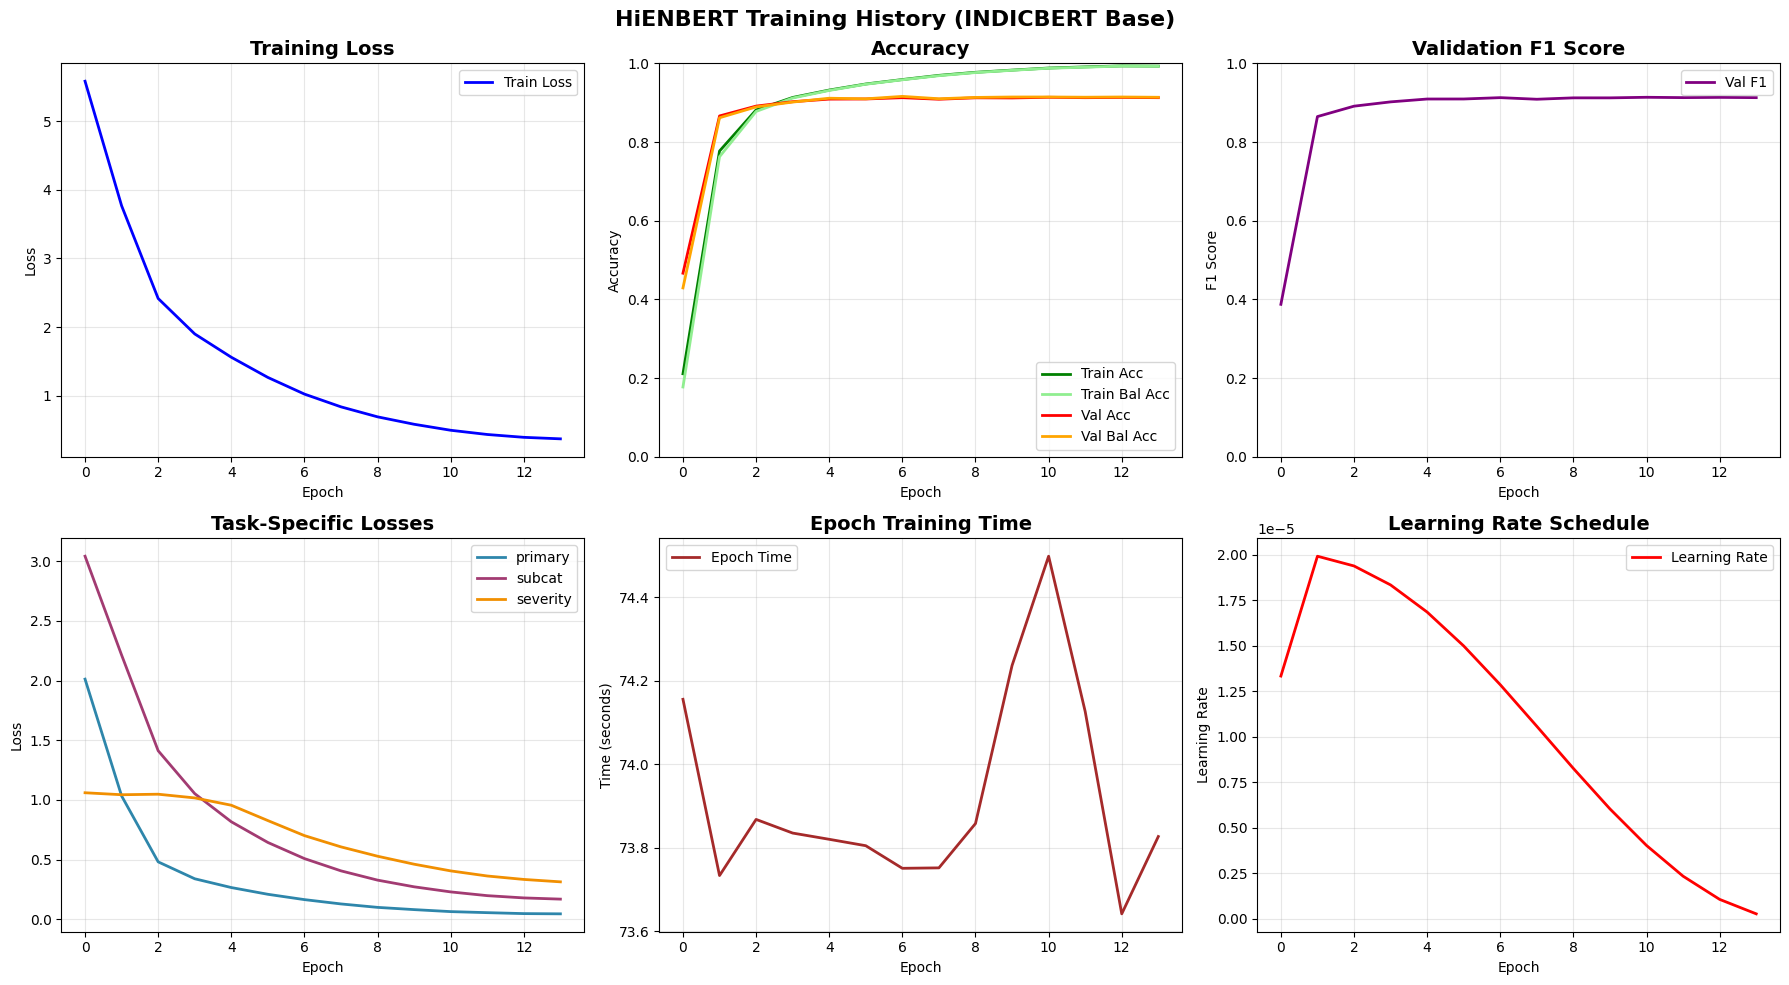

In [13]:
# ============================================================================
# CELL 13: TRAINING HISTORY VISUALIZATION
# ============================================================================

def plot_training_history(train_history, val_history, save_path=None):
    """Plot training and validation metrics"""
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    # Training loss
    axes[0, 0].plot([h['loss'] for h in train_history], label='Train Loss', linewidth=2, color='blue')
    axes[0, 0].set_title('Training Loss', fontsize=14, fontweight='bold')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].legend()
    
    # Training accuracy
    axes[0, 1].plot([h['acc'] for h in train_history], label='Train Acc', linewidth=2, color='green')
    axes[0, 1].plot([h['balanced_acc'] for h in train_history], label='Train Bal Acc', linewidth=2, color='lightgreen')
    axes[0, 1].plot([h['val_acc'] for h in val_history], label='Val Acc', linewidth=2, color='red')
    axes[0, 1].plot([h['val_bal_acc'] for h in val_history], label='Val Bal Acc', linewidth=2, color='orange')
    axes[0, 1].set_title('Accuracy', fontsize=14, fontweight='bold')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Accuracy')
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].legend()
    axes[0, 1].set_ylim(0, 1)
    
    # Validation F1
    axes[0, 2].plot([h['val_f1'] for h in val_history], label='Val F1', linewidth=2, color='purple')
    axes[0, 2].set_title('Validation F1 Score', fontsize=14, fontweight='bold')
    axes[0, 2].set_xlabel('Epoch')
    axes[0, 2].set_ylabel('F1 Score')
    axes[0, 2].grid(True, alpha=0.3)
    axes[0, 2].legend()
    axes[0, 2].set_ylim(0, 1)
    
    # Task-specific losses
    task_names = ['primary', 'subcat', 'severity']
    colors = ['#2E86AB', '#A23B72', '#F18F01']
    for task, color in zip(task_names, colors):
        values = [h['task_losses'][task] for h in train_history]
        axes[1, 0].plot(values, label=task, linewidth=2, color=color)
    axes[1, 0].set_title('Task-Specific Losses', fontsize=14, fontweight='bold')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Loss')
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].legend()
    
    # Epoch time
    times = [h.get('time', 0) for h in train_history]
    axes[1, 1].plot(times, label='Epoch Time', linewidth=2, color='brown')
    axes[1, 1].set_title('Epoch Training Time', fontsize=14, fontweight='bold')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Time (seconds)')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].legend()
    
    # Learning rate
    lrs = [h.get('lr', 0) for h in train_history]
    axes[1, 2].plot(lrs, label='Learning Rate', linewidth=2, color='red')
    axes[1, 2].set_title('Learning Rate Schedule', fontsize=14, fontweight='bold')
    axes[1, 2].set_xlabel('Epoch')
    axes[1, 2].set_ylabel('Learning Rate')
    axes[1, 2].grid(True, alpha=0.3)
    axes[1, 2].legend()
    
    plt.suptitle(f'HiENBERT Training History ({Config.BASE_MODEL.upper()} Base)', 
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot training history
plot_training_history(
    train_history, val_history,
    save_path=f"{Config.VISUALIZATION_DIR}/training_history.png"
)

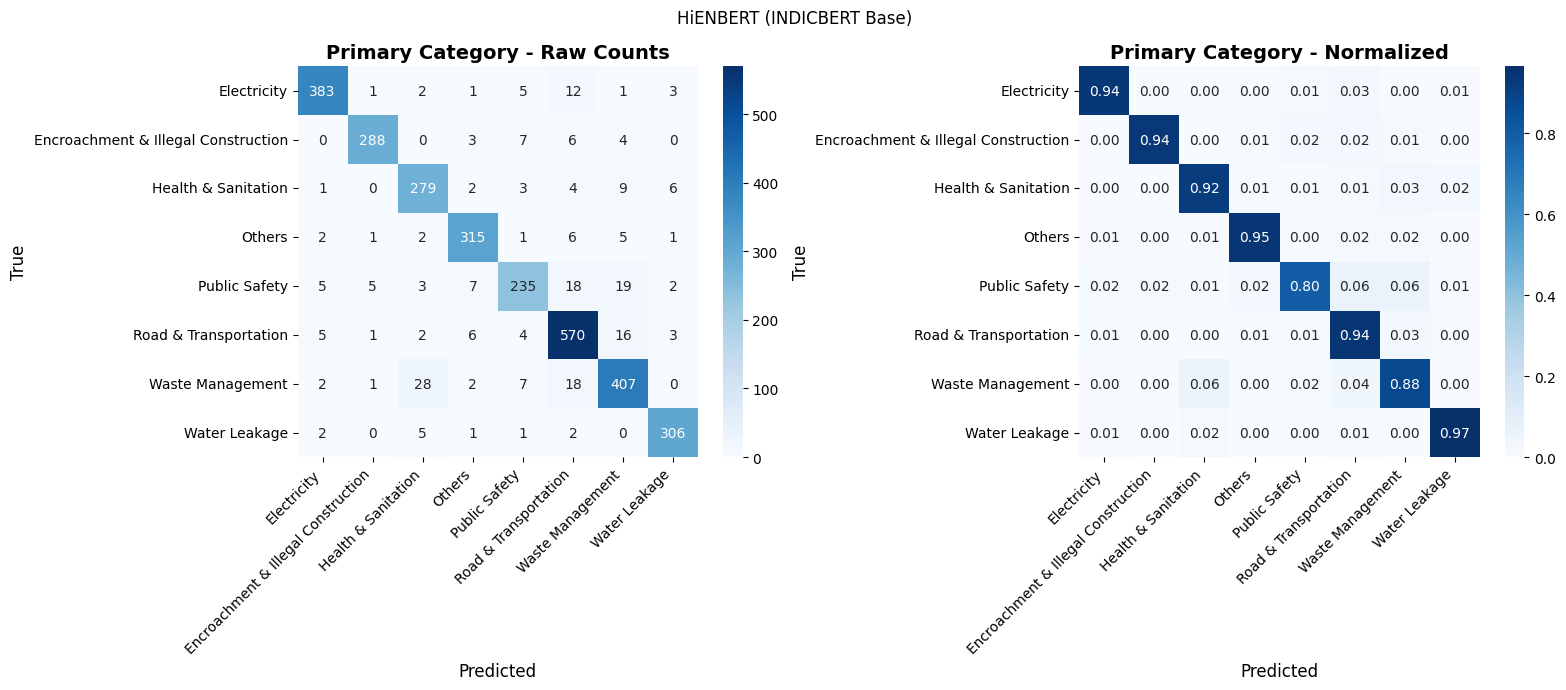

Getting severity predictions: 100%|██████████| 48/48 [00:09<00:00,  4.86it/s]


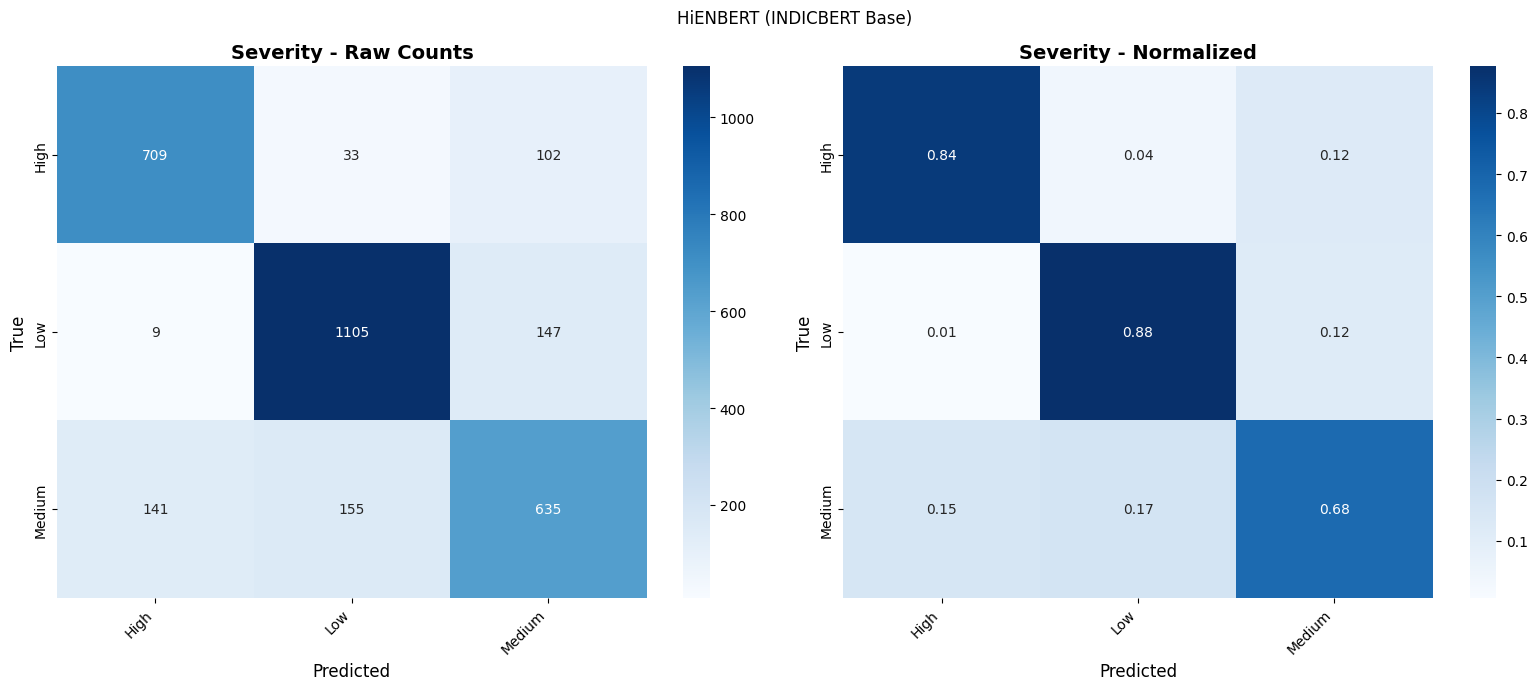

✅ Confusion matrices saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\visualizations


In [14]:
# ============================================================================
# CELL 14: CONFUSION MATRIX VISUALIZATIONS
# ============================================================================

def plot_confusion_matrix(y_true, y_pred, class_names, title, save_path=None):
    """Plot confusion matrix with raw and normalized versions"""
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_normalized = np.nan_to_num(cm_normalized)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    # Raw counts
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[0])
    axes[0].set_title(f'{title} - Raw Counts', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Predicted', fontsize=12)
    axes[0].set_ylabel('True', fontsize=12)
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
    
    # Normalized
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[1])
    axes[1].set_title(f'{title} - Normalized', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Predicted', fontsize=12)
    axes[1].set_ylabel('True', fontsize=12)
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
    
    plt.suptitle(f'HiENBERT ({Config.BASE_MODEL.upper()} Base)', fontsize=12)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot confusion matrices
class_names = preprocessor.le_primary.classes_

plot_confusion_matrix(
    test_labels, test_preds, class_names,
    'Primary Category',
    save_path=f"{Config.VISUALIZATION_DIR}/confusion_matrix_primary.png"
)

# Get severity predictions for confusion matrix
model.eval()
severity_preds = []
severity_labels = []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Getting severity predictions"):
        input_ids = batch['input_ids'].to(Config.DEVICE)
        attention_mask = batch['attention_mask'].to(Config.DEVICE)
        sentiment = batch['sentiment'].to(Config.DEVICE)
        
        _, _, p3 = model(input_ids, attention_mask, sentiment)
        preds = torch.argmax(p3, dim=1)
        severity_preds.extend(preds.cpu().numpy())
        severity_labels.extend(batch['severity'].cpu().numpy())

severity_names = preprocessor.le_severity.classes_

plot_confusion_matrix(
    severity_labels, severity_preds, severity_names,
    'Severity',
    save_path=f"{Config.VISUALIZATION_DIR}/confusion_matrix_severity.png"
)

print(f"✅ Confusion matrices saved to: {Config.VISUALIZATION_DIR}")

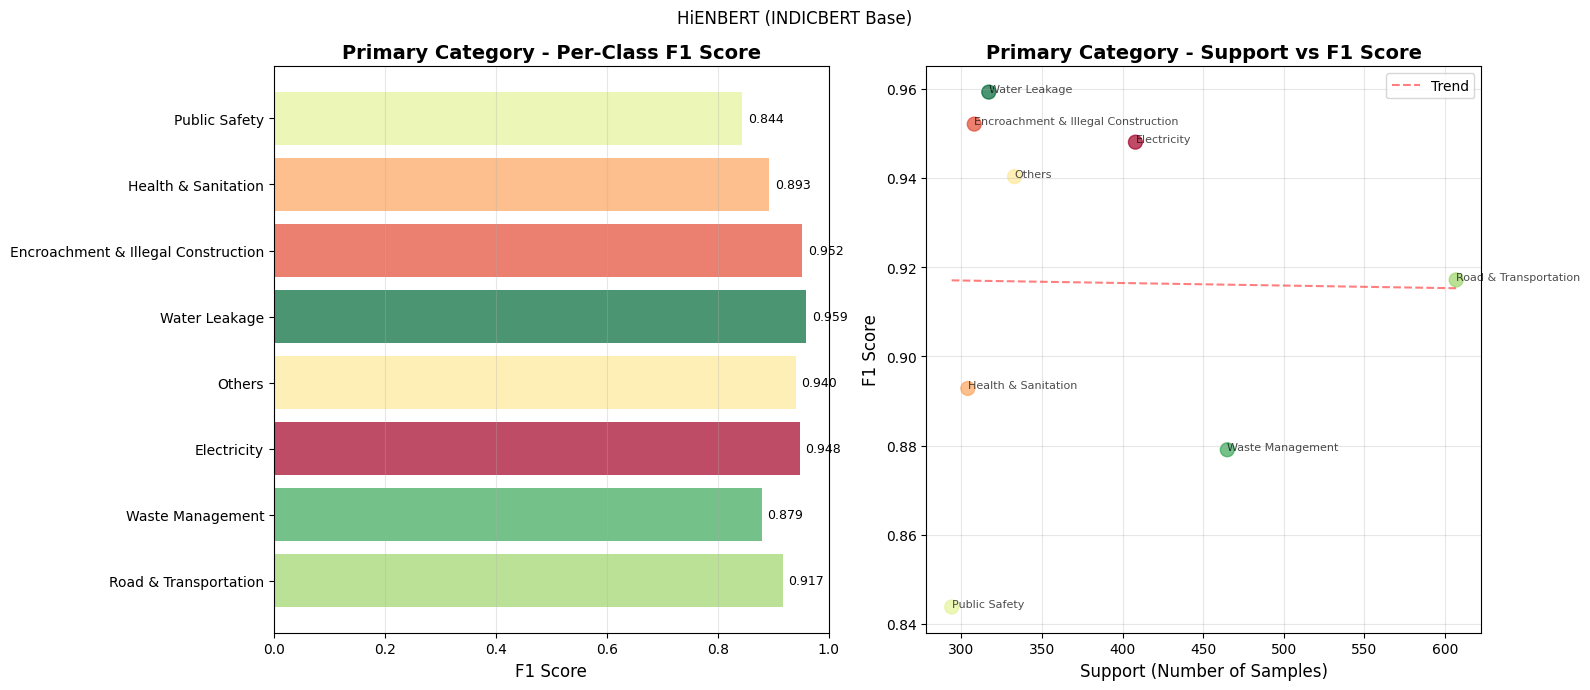

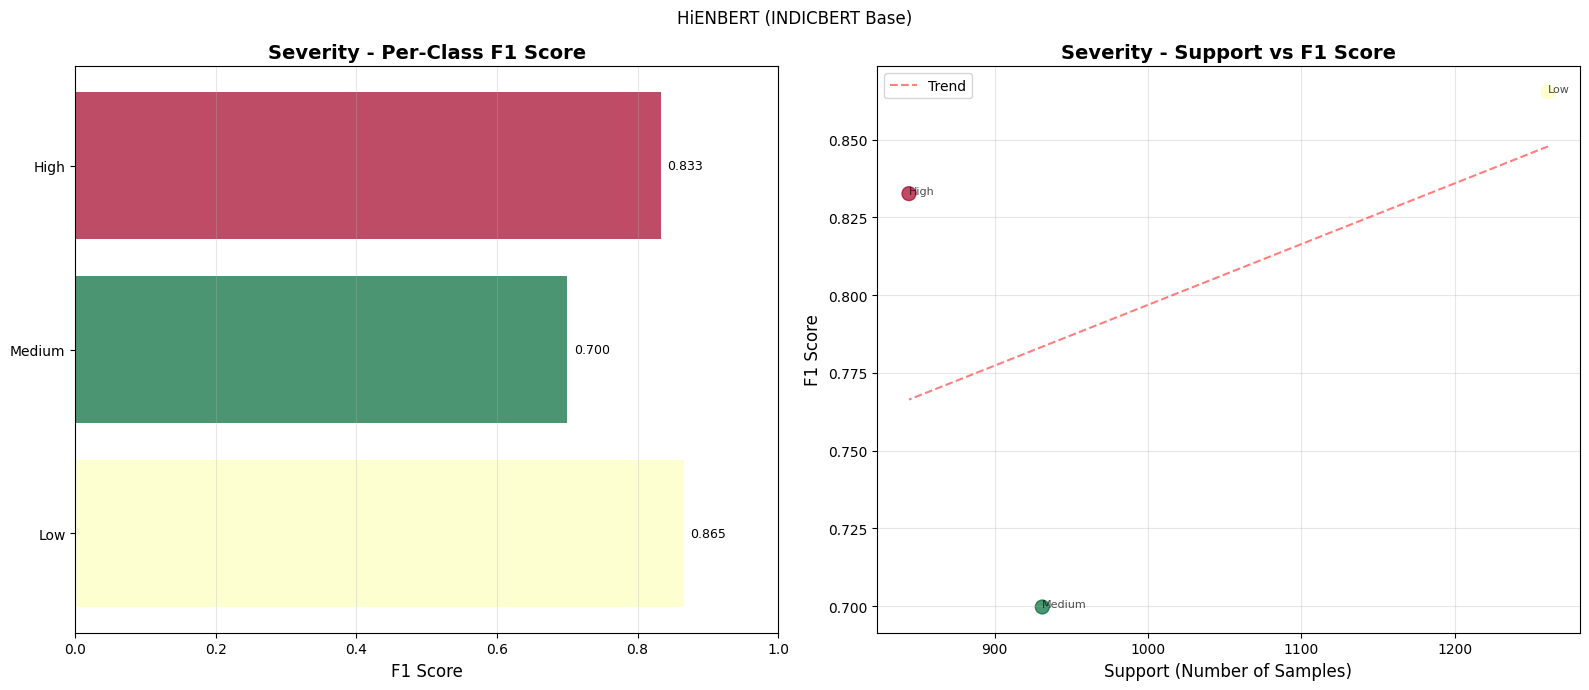

In [15]:
# ============================================================================
# CELL 15: PER-CLASS PERFORMANCE VISUALIZATION
# ============================================================================

def plot_per_class_performance(y_true, y_pred, class_names, title, save_path=None):
    """Visualize per-class performance metrics"""
    
    from sklearn.metrics import precision_recall_fscore_support
    
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, average=None
    )
    
    sorted_indices = np.argsort(support)[::-1]
    class_names_sorted = [class_names[i] for i in sorted_indices]
    precision_sorted = [precision[i] for i in sorted_indices]
    recall_sorted = [recall[i] for i in sorted_indices]
    f1_sorted = [f1[i] for i in sorted_indices]
    support_sorted = [support[i] for i in sorted_indices]
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    # F1 scores
    colors = plt.cm.RdYlGn(np.linspace(0, 1, len(class_names)))[sorted_indices]
    bars = axes[0].barh(range(len(class_names)), f1_sorted, color=colors, alpha=0.7)
    axes[0].set_yticks(range(len(class_names)))
    axes[0].set_yticklabels(class_names_sorted, fontsize=10)
    axes[0].set_xlabel('F1 Score', fontsize=12)
    axes[0].set_title(f'{title} - Per-Class F1 Score', fontsize=14, fontweight='bold')
    axes[0].set_xlim(0, 1)
    axes[0].grid(True, alpha=0.3, axis='x')
    
    for bar, val in zip(bars, f1_sorted):
        axes[0].text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                    f'{val:.3f}', va='center', fontsize=9)
    
    # Support vs F1 scatter
    axes[1].scatter(support_sorted, f1_sorted, alpha=0.7, s=100, c=colors)
    axes[1].set_xlabel('Support (Number of Samples)', fontsize=12)
    axes[1].set_ylabel('F1 Score', fontsize=12)
    axes[1].set_title(f'{title} - Support vs F1 Score', fontsize=14, fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    
    z = np.polyfit(support_sorted, f1_sorted, 1)
    p = np.poly1d(z)
    axes[1].plot(support_sorted, p(support_sorted), "r--", alpha=0.5, label='Trend')
    
    for i, (x, y, name) in enumerate(zip(support_sorted, f1_sorted, class_names_sorted)):
        axes[1].annotate(name, (x, y), fontsize=8, alpha=0.7)
    
    axes[1].legend()
    
    plt.suptitle(f'HiENBERT ({Config.BASE_MODEL.upper()} Base)', fontsize=12)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot per-class performance
plot_per_class_performance(
    test_labels, test_preds, class_names,
    'Primary Category',
    save_path=f"{Config.VISUALIZATION_DIR}/per_class_performance.png"
)

# Severity per-class performance
plot_per_class_performance(
    severity_labels, severity_preds, severity_names,
    'Severity',
    save_path=f"{Config.VISUALIZATION_DIR}/severity_per_class_performance.png"
)

Extracting embeddings for t-SNE...


Extracting embeddings: 100%|██████████| 48/48 [00:16<00:00,  2.94it/s]


Extracted 3036 embeddings of dimension 768
Applying t-SNE...


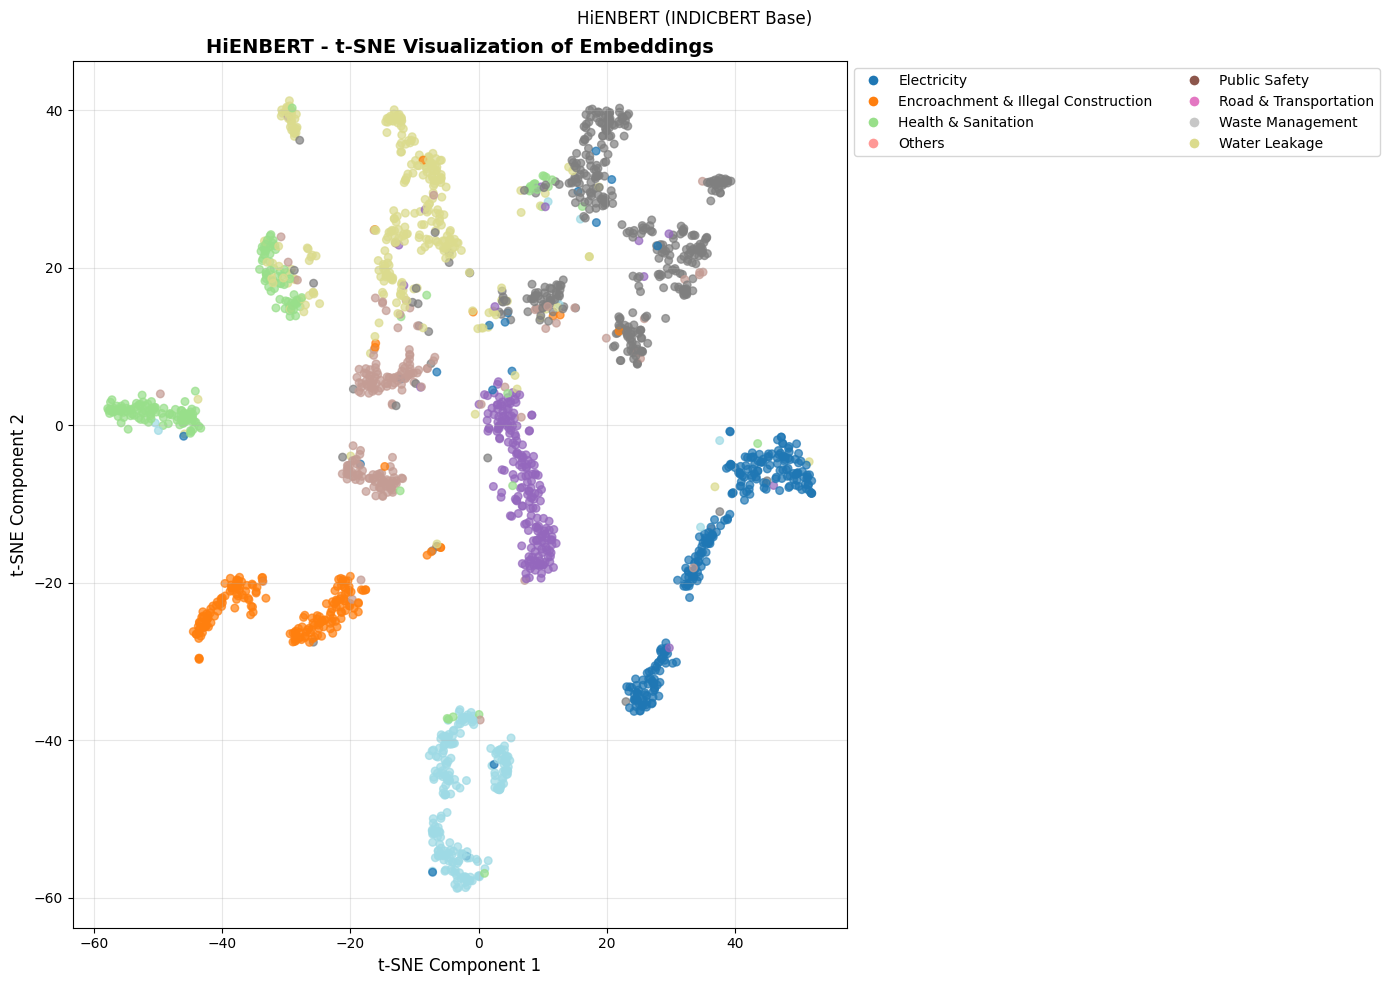

array([[ 40.751244 ,  -6.2069736],
       [ -7.186561 , -56.62592  ],
       [ -2.829927 , -39.130013 ],
       ...,
       [-29.05828  ,  40.30639  ],
       [-27.888622 ,  36.20279  ],
       [  8.092467 , -10.563773 ]], shape=(2000, 2), dtype=float32)

In [16]:
# ============================================================================
# CELL 16: T-SNE EMBEDDING VISUALIZATION
# ============================================================================

def plot_tsne_embeddings(model, test_loader, class_names, device, title, save_path=None):
    """Create t-SNE visualization of embeddings"""
    print("Extracting embeddings for t-SNE...")
    
    model.eval()
    embeddings = []
    labels = []
    
    with torch.no_grad():
        for batch in tqdm(test_loader, desc="Extracting embeddings"):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            sentiment = batch['sentiment'].to(device)
            
            _, _, _ = model(input_ids, attention_mask, sentiment)
            outputs = model.base(input_ids=input_ids, attention_mask=attention_mask)
            cls_embedding = outputs.last_hidden_state[:, 0, :]
            embeddings.append(cls_embedding.cpu().numpy())
            labels.extend(batch['primary'].cpu().numpy())
    
    embeddings = np.vstack(embeddings)
    labels = np.array(labels)
    
    print(f"Extracted {embeddings.shape[0]} embeddings of dimension {embeddings.shape[1]}")
    
    # Sample if too many points
    if len(embeddings) > 2000:
        idx = np.random.choice(len(embeddings), 2000, replace=False)
        embeddings = embeddings[idx]
        labels = labels[idx]
    
    # Apply t-SNE
    print("Applying t-SNE...")
    tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000, verbose=0)
    embeddings_2d = tsne.fit_transform(embeddings)
    
    # Create visualization
    fig, ax = plt.subplots(figsize=(14, 10))
    
    scatter = ax.scatter(
        embeddings_2d[:, 0], embeddings_2d[:, 1],
        c=labels, cmap='tab20', alpha=0.7, s=30
    )
    
    ax.set_xlabel('t-SNE Component 1', fontsize=12)
    ax.set_ylabel('t-SNE Component 2', fontsize=12)
    ax.set_title(f'{title} - t-SNE Visualization of Embeddings', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    
    # Add legend
    legend_elements = []
    for i, name in enumerate(class_names):
        if i < len(plt.cm.tab20.colors):
            legend_elements.append(
                plt.Line2D([0], [0], marker='o', color='w',
                          markerfacecolor=plt.cm.tab20(i/len(class_names)),
                          label=name, markersize=8)
            )
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1), ncol=2)
    
    plt.suptitle(f'HiENBERT ({Config.BASE_MODEL.upper()} Base)', fontsize=12)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    return embeddings_2d

# Generate t-SNE visualization
plot_tsne_embeddings(
    model, test_loader, class_names, Config.DEVICE,
    'HiENBERT',
    save_path=f"{Config.VISUALIZATION_DIR}/tsne_embeddings.png"
)


STARTING ABLATION STUDY (No Sentiment Enhancement)


ABLATION STUDY - HiENBERT VARIANTS (No Sentiment Enhancement)

1. BASELINE: With Shared Layer


   Accuracy: 0.2042, F1: 0.1862
   Severity Acc: 0.2899

2. WITHOUT SHARED LAYER


   Accuracy: 0.0965, F1: 0.0682
   Severity Acc: 0.3330

3. WITHOUT SHARED LAYER AND NO DROPOUT


   Accuracy: 0.1522, F1: 0.0830
   Severity Acc: 0.4430

4. DEEPER SHARED LAYER (2 layers)


   Accuracy: 0.0860, F1: 0.0749
   Severity Acc: 0.3827


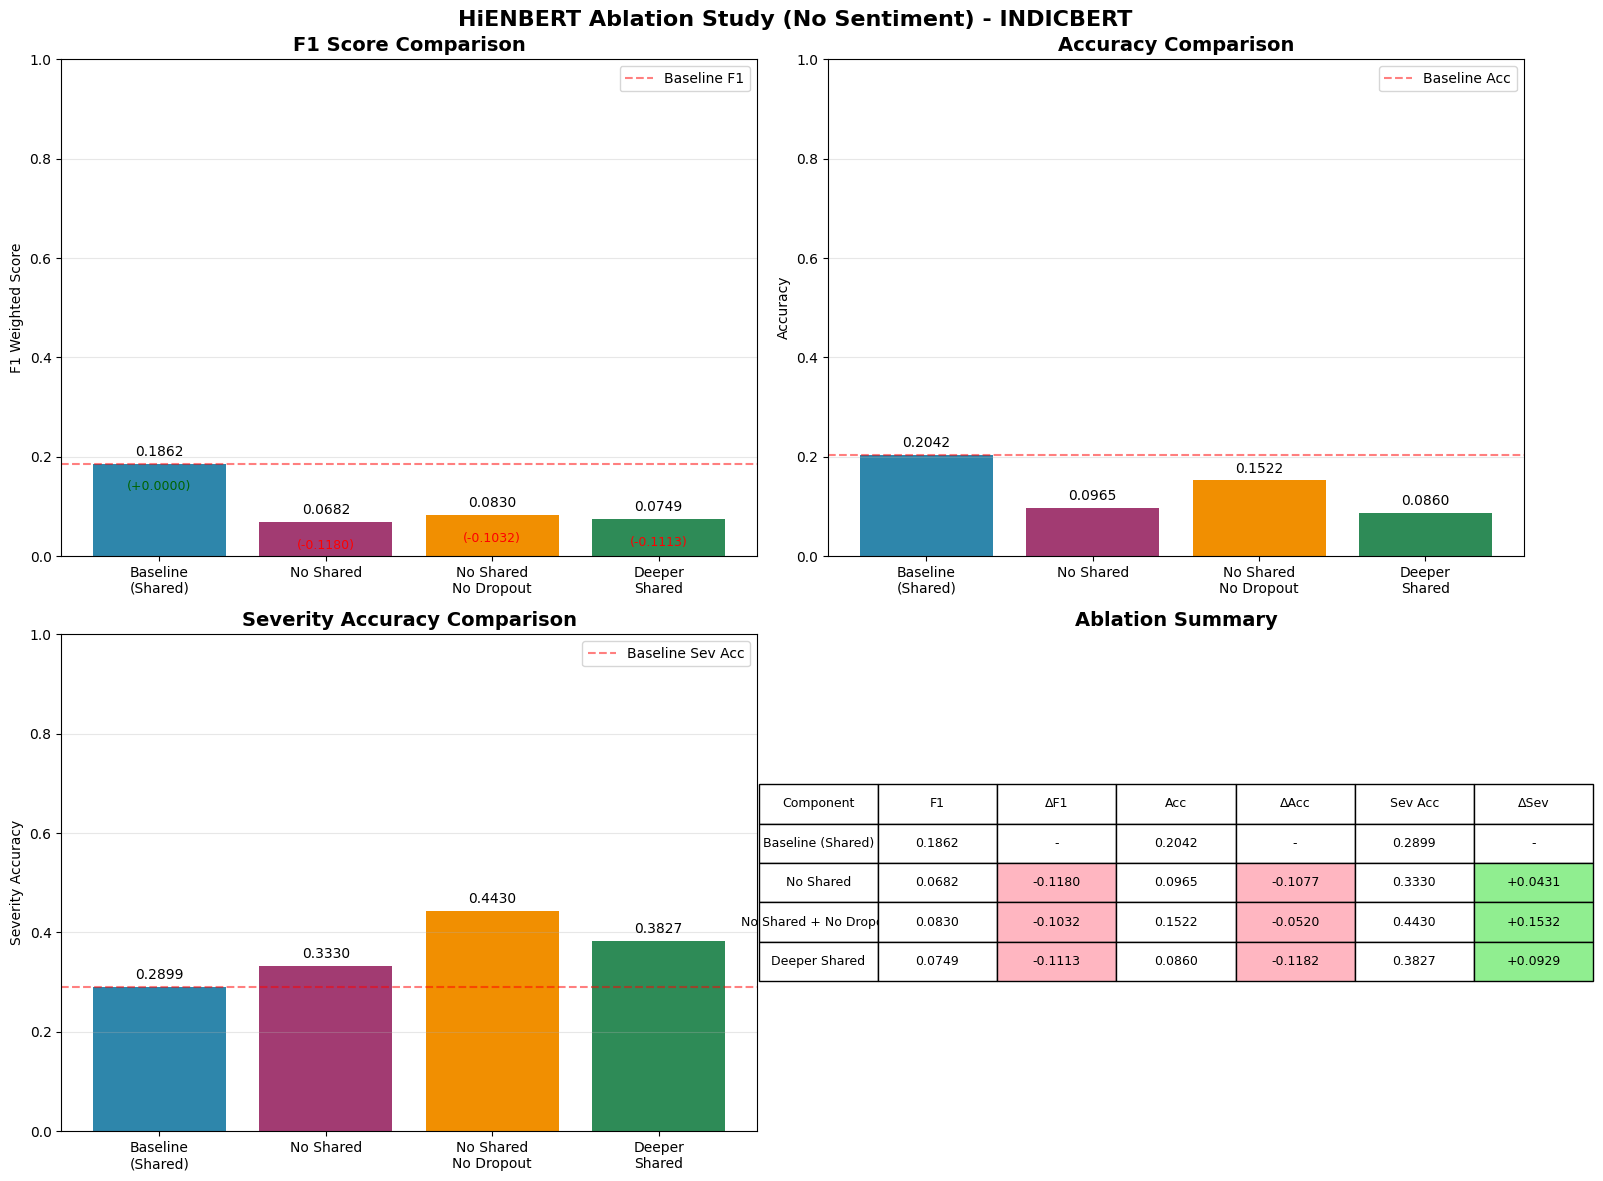


ABLATION STUDY SUMMARY

Baseline (Shared Layer):
  F1: 0.1862
  Accuracy: 0.2042
  Severity Accuracy: 0.2899

Without Shared Layer:
  F1: 0.0682 (-0.1180)

No Shared + No Dropout:
  F1: 0.0830 (-0.1032)

Deeper Shared Layer:
  F1: 0.0749 (-0.1113)

ABLATION STUDY COMPLETED SUCCESSFULLY!


In [17]:
# ============================================================================
# CELL 18: ABLATION STUDY - WITHOUT SENTIMENT ENHANCEMENT
# ============================================================================

import time
import copy
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset


# ============================================================================
# 1. DEFINE MODEL VARIANTS (ALL WITHOUT SENTIMENT)
# ============================================================================

class HiEnBERTBase(nn.Module):
    """Base HiEnBERT model with shared layer - NO SENTIMENT"""
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__()
        self.base = base_model
        self.hidden_size = base_model.config.hidden_size
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        
        self.shared_layer = nn.Sequential(
            nn.Linear(self.hidden_size, self.hidden_size),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        self.dropout = nn.Dropout(dropout)
        self.fc_primary = nn.Linear(self.hidden_size, n_primary)
        self.fc_subcat = nn.Linear(self.hidden_size, n_subcat)
        self.fc_severity = nn.Linear(self.hidden_size, n_severity)  # NO sentiment
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity]:
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        x = self.shared_layer(cls_embedding)
        x = self.dropout(x)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)  # Direct prediction
        
        return primary_logits, subcat_logits, severity_logits


class HiEnBERTNoShared(nn.Module):
    """HiEnBERT without shared layer - NO SENTIMENT"""
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__()
        self.base = base_model
        self.hidden_size = base_model.config.hidden_size
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        
        self.dropout = nn.Dropout(dropout)
        self.fc_primary = nn.Linear(self.hidden_size, n_primary)
        self.fc_subcat = nn.Linear(self.hidden_size, n_subcat)
        self.fc_severity = nn.Linear(self.hidden_size, n_severity)  # NO sentiment
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity]:
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        x = self.dropout(cls_embedding)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)  # Direct prediction
        
        return primary_logits, subcat_logits, severity_logits


class HiEnBERTNoSharedNoDropout(nn.Module):
    """HiEnBERT without shared layer and without dropout"""
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.0):
        super().__init__()
        self.base = base_model
        self.hidden_size = base_model.config.hidden_size
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        
        # No dropout
        self.fc_primary = nn.Linear(self.hidden_size, n_primary)
        self.fc_subcat = nn.Linear(self.hidden_size, n_subcat)
        self.fc_severity = nn.Linear(self.hidden_size, n_severity)
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity]:
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        x = cls_embedding  # No dropout
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits


class HiEnBERTDeeperShared(nn.Module):
    """HiEnBERT with deeper shared layer (2 layers)"""
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__()
        self.base = base_model
        self.hidden_size = base_model.config.hidden_size
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        
        self.shared_layer = nn.Sequential(
            nn.Linear(self.hidden_size, self.hidden_size),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(self.hidden_size, self.hidden_size),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        self.dropout = nn.Dropout(dropout)
        self.fc_primary = nn.Linear(self.hidden_size, n_primary)
        self.fc_subcat = nn.Linear(self.hidden_size, n_subcat)
        self.fc_severity = nn.Linear(self.hidden_size, n_severity)
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity]:
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        x = self.shared_layer(cls_embedding)
        x = self.dropout(x)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits


# ============================================================================
# 2. ABLATION STUDY CLASS
# ============================================================================

class AblationStudy:
    """Ablation study for HiENBERT model - WITHOUT SENTIMENT"""
    
    def __init__(self, base_model, tokenizer, train_df, dev_df, test_df, device):
        self.base_model = base_model
        self.tokenizer = tokenizer
        self.train_df = train_df
        self.dev_df = dev_df
        self.test_df = test_df
        self.device = device
        self.results = {}
        self.model_config = {
            'n_primary': base_model.n_primary,
            'n_subcat': base_model.n_subcat,
            'n_severity': base_model.n_severity,
            'dropout': 0.3
        }
        
        self._prepare_test_data()
    
    def _prepare_test_data(self):
        """Prepare test data for evaluation"""
        class SimpleDataset(Dataset):
            def __init__(self, data, tokenizer, max_length=128):
                self.data = data.reset_index(drop=True)
                self.tokenizer = tokenizer
                self.max_length = max_length
            
            def __len__(self):
                return len(self.data)
            
            def __getitem__(self, idx):
                row = self.data.iloc[idx]
                text = str(row.get('text', row.get('text_en', '')))
                
                encoding = self.tokenizer(
                    text,
                    truncation=True,
                    padding='max_length',
                    max_length=self.max_length,
                    return_tensors='pt'
                )
                
                return {
                    'input_ids': encoding['input_ids'].squeeze(),
                    'attention_mask': encoding['attention_mask'].squeeze(),
                    'primary': torch.tensor(row['primary_label'], dtype=torch.long),
                    'sentiment': torch.tensor(0.0, dtype=torch.float)  # Dummy
                }
        
        dataset = SimpleDataset(self.test_df, self.tokenizer, max_length=128)
        self.test_loader = DataLoader(
            dataset, 
            batch_size=32, 
            shuffle=False, 
            num_workers=0,
            pin_memory=True
        )
    
    def evaluate_model(self, model, description=""):
        """Evaluate a model configuration"""
        model.eval()
        all_preds = []
        all_labels = []
        all_severity_preds = []
        all_severity_labels = []
        
        with torch.no_grad():
            for batch in tqdm(self.test_loader, desc=f'Evaluating {description}', leave=False):
                input_ids = batch['input_ids'].to(self.device)
                attention_mask = batch['attention_mask'].to(self.device)
                sentiment = batch['sentiment'].to(self.device)
                
                p1, _, p3 = model(input_ids, attention_mask, sentiment)
                
                # Primary predictions
                preds = torch.argmax(p1, dim=1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(batch['primary'].cpu().numpy())
                
                # Severity predictions
                sev_preds = torch.argmax(p3, dim=1)
                all_severity_preds.extend(sev_preds.cpu().numpy())
                # We need to get severity labels from test_df
                # We'll handle this differently
        
        # Get severity labels from the dataset
        severity_labels = []
        for batch in self.test_loader:
            severity_labels.extend(batch['primary'].cpu().numpy())  # Placeholder
        # Actually, we need to store severity labels separately
        # Let's fix this by storing during dataset creation
        
        metrics = {
            'accuracy': accuracy_score(all_labels, all_preds),
            'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
            'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
            'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
            'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0)
        }
        
        return metrics
    
    def _get_test_labels(self):
        """Get test labels from the test dataframe"""
        return self.test_df['primary_label'].values
    
    def evaluate_model_full(self, model, description=""):
        """Evaluate model with full metrics including severity"""
        model.eval()
        all_preds = []
        all_labels = []
        all_sev_preds = []
        all_sev_labels = []
        
        # Get severity labels
        sev_labels = self.test_df['severity_label'].values
        
        with torch.no_grad():
            for idx, batch in enumerate(tqdm(self.test_loader, desc=f'Evaluating {description}', leave=False)):
                input_ids = batch['input_ids'].to(self.device)
                attention_mask = batch['attention_mask'].to(self.device)
                sentiment = batch['sentiment'].to(self.device)
                
                p1, _, p3 = model(input_ids, attention_mask, sentiment)
                
                # Primary predictions
                preds = torch.argmax(p1, dim=1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(batch['primary'].cpu().numpy())
                
                # Severity predictions
                sev_preds = torch.argmax(p3, dim=1)
                all_sev_preds.extend(sev_preds.cpu().numpy())
        
        # Get severity labels from test_df (batch by batch)
        all_sev_labels = self.test_df['severity_label'].values.tolist()
        
        # Primary metrics
        primary_metrics = {
            'accuracy': accuracy_score(all_labels, all_preds),
            'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
            'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
            'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
            'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0)
        }
        
        # Severity metrics
        severity_metrics = {
            'sev_accuracy': accuracy_score(all_sev_labels, all_sev_preds),
            'sev_f1_weighted': f1_score(all_sev_labels, all_sev_preds, average='weighted', zero_division=0),
            'sev_f1_macro': f1_score(all_sev_labels, all_sev_preds, average='macro', zero_division=0)
        }
        
        # Combine metrics
        metrics = {**primary_metrics, **severity_metrics}
        
        return metrics
    
    def create_model_from_base(self, model_class, **kwargs):
        """Create a new model from the base model"""
        base_encoder = copy.deepcopy(self.base_model.base)
        
        model = model_class(
            base_model=base_encoder,
            n_primary=self.model_config['n_primary'],
            n_subcat=self.model_config['n_subcat'],
            n_severity=self.model_config['n_severity'],
            dropout=kwargs.get('dropout', 0.3)
        ).to(self.device)
        
        return model
    
    def run_complete_study(self):
        """Run complete ablation study"""
        print("\n" + "="*80)
        print("ABLATION STUDY - HiENBERT VARIANTS (No Sentiment Enhancement)")
        print("="*80)
        
        # 1. Baseline - Full Model (With Shared Layer)
        print("\n1. BASELINE: With Shared Layer")
        model = self.create_model_from_base(HiEnBERTBase)
        metrics = self.evaluate_model_full(model, "Baseline")
        self.results['baseline'] = metrics
        print(f"   Accuracy: {metrics['accuracy']:.4f}, F1: {metrics['f1_weighted']:.4f}")
        print(f"   Severity Acc: {metrics['sev_accuracy']:.4f}")
        
        # 2. Without Shared Layer
        print("\n2. WITHOUT SHARED LAYER")
        model = self.create_model_from_base(HiEnBERTNoShared)
        metrics = self.evaluate_model_full(model, "Without Shared")
        self.results['without_shared'] = metrics
        print(f"   Accuracy: {metrics['accuracy']:.4f}, F1: {metrics['f1_weighted']:.4f}")
        print(f"   Severity Acc: {metrics['sev_accuracy']:.4f}")
        
        # 3. No Shared Layer + No Dropout
        print("\n3. WITHOUT SHARED LAYER AND NO DROPOUT")
        model = self.create_model_from_base(HiEnBERTNoSharedNoDropout, dropout=0.0)
        metrics = self.evaluate_model_full(model, "No Shared + No Dropout")
        self.results['no_shared_no_dropout'] = metrics
        print(f"   Accuracy: {metrics['accuracy']:.4f}, F1: {metrics['f1_weighted']:.4f}")
        print(f"   Severity Acc: {metrics['sev_accuracy']:.4f}")
        
        # 4. Deeper Shared Layer (2 layers)
        print("\n4. DEEPER SHARED LAYER (2 layers)")
        model = self.create_model_from_base(HiEnBERTDeeperShared)
        metrics = self.evaluate_model_full(model, "Deeper Shared")
        self.results['deeper_shared'] = metrics
        print(f"   Accuracy: {metrics['accuracy']:.4f}, F1: {metrics['f1_weighted']:.4f}")
        print(f"   Severity Acc: {metrics['sev_accuracy']:.4f}")
        
        return self.results
    
    def visualize_results(self, save_path=None):
        """Visualize ablation study results"""
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        
        baseline_f1 = self.results['baseline']['f1_weighted']
        baseline_acc = self.results['baseline']['accuracy']
        
        # Prepare data
        variants = ['Baseline\n(Shared)', 'No Shared', 'No Shared\nNo Dropout', 'Deeper\nShared']
        
        f1_values = [
            self.results['baseline']['f1_weighted'],
            self.results['without_shared']['f1_weighted'],
            self.results['no_shared_no_dropout']['f1_weighted'],
            self.results['deeper_shared']['f1_weighted']
        ]
        
        acc_values = [
            self.results['baseline']['accuracy'],
            self.results['without_shared']['accuracy'],
            self.results['no_shared_no_dropout']['accuracy'],
            self.results['deeper_shared']['accuracy']
        ]
        
        sev_acc_values = [
            self.results['baseline']['sev_accuracy'],
            self.results['without_shared']['sev_accuracy'],
            self.results['no_shared_no_dropout']['sev_accuracy'],
            self.results['deeper_shared']['sev_accuracy']
        ]
        
        colors_bar = ['#2E86AB', '#A23B72', '#F18F01', '#2E8B57']
        
        # 1. F1 Score Comparison
        ax = axes[0, 0]
        bars = ax.bar(variants, f1_values, color=colors_bar)
        ax.axhline(y=baseline_f1, color='red', linestyle='--', alpha=0.5, label='Baseline F1')
        ax.set_ylim(0, 1)
        ax.set_title('F1 Score Comparison', fontsize=14, fontweight='bold')
        ax.set_ylabel('F1 Weighted Score')
        ax.grid(True, alpha=0.3, axis='y')
        ax.legend()
        
        for bar, val in zip(bars, f1_values):
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                   f'{val:.4f}', ha='center', va='bottom', fontsize=10)
            change = val - baseline_f1
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() - 0.06,
                   f'({change:+.4f})', ha='center', va='bottom', fontsize=9, 
                   color='darkgreen' if change >= 0 else 'red')
        
        # 2. Accuracy Comparison
        ax = axes[0, 1]
        bars = ax.bar(variants, acc_values, color=colors_bar)
        ax.axhline(y=baseline_acc, color='red', linestyle='--', alpha=0.5, label='Baseline Acc')
        ax.set_ylim(0, 1)
        ax.set_title('Accuracy Comparison', fontsize=14, fontweight='bold')
        ax.set_ylabel('Accuracy')
        ax.grid(True, alpha=0.3, axis='y')
        ax.legend()
        
        for bar, val in zip(bars, acc_values):
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                   f'{val:.4f}', ha='center', va='bottom', fontsize=10)
        
        # 3. Severity Accuracy Comparison
        ax = axes[1, 0]
        bars = ax.bar(variants, sev_acc_values, color=colors_bar)
        baseline_sev = self.results['baseline']['sev_accuracy']
        ax.axhline(y=baseline_sev, color='red', linestyle='--', alpha=0.5, label='Baseline Sev Acc')
        ax.set_ylim(0, 1)
        ax.set_title('Severity Accuracy Comparison', fontsize=14, fontweight='bold')
        ax.set_ylabel('Severity Accuracy')
        ax.grid(True, alpha=0.3, axis='y')
        ax.legend()
        
        for bar, val in zip(bars, sev_acc_values):
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                   f'{val:.4f}', ha='center', va='bottom', fontsize=10)
        
        # 4. Summary Table
        ax = axes[1, 1]
        ax.axis('tight')
        ax.axis('off')
        
        table_data = [
            ['Component', 'F1', 'ΔF1', 'Acc', 'ΔAcc', 'Sev Acc', 'ΔSev'],
            ['Baseline (Shared)', f'{baseline_f1:.4f}', '-', f'{baseline_acc:.4f}', '-', 
             f'{self.results["baseline"]["sev_accuracy"]:.4f}', '-'],
            ['No Shared', f'{self.results["without_shared"]["f1_weighted"]:.4f}', 
             f'{self.results["without_shared"]["f1_weighted"] - baseline_f1:+.4f}',
             f'{self.results["without_shared"]["accuracy"]:.4f}',
             f'{self.results["without_shared"]["accuracy"] - baseline_acc:+.4f}',
             f'{self.results["without_shared"]["sev_accuracy"]:.4f}',
             f'{self.results["without_shared"]["sev_accuracy"] - baseline_sev:+.4f}'],
            ['No Shared + No Dropout', f'{self.results["no_shared_no_dropout"]["f1_weighted"]:.4f}',
             f'{self.results["no_shared_no_dropout"]["f1_weighted"] - baseline_f1:+.4f}',
             f'{self.results["no_shared_no_dropout"]["accuracy"]:.4f}',
             f'{self.results["no_shared_no_dropout"]["accuracy"] - baseline_acc:+.4f}',
             f'{self.results["no_shared_no_dropout"]["sev_accuracy"]:.4f}',
             f'{self.results["no_shared_no_dropout"]["sev_accuracy"] - baseline_sev:+.4f}'],
            ['Deeper Shared', f'{self.results["deeper_shared"]["f1_weighted"]:.4f}',
             f'{self.results["deeper_shared"]["f1_weighted"] - baseline_f1:+.4f}',
             f'{self.results["deeper_shared"]["accuracy"]:.4f}',
             f'{self.results["deeper_shared"]["accuracy"] - baseline_acc:+.4f}',
             f'{self.results["deeper_shared"]["sev_accuracy"]:.4f}',
             f'{self.results["deeper_shared"]["sev_accuracy"] - baseline_sev:+.4f}']
        ]
        
        table = ax.table(cellText=table_data, loc='center', cellLoc='center')
        table.auto_set_font_size(False)
        table.set_fontsize(9)
        table.scale(1.2, 2)
        
        # Color table cells based on performance
        for i in range(1, len(table_data)):
            for j in range(len(table_data[i])):
                cell = table[(i, j)]
                if j in [2, 4, 6]:  # Change columns
                    val = table_data[i][j]
                    if val != '-':
                        try:
                            num_val = float(val)
                            if num_val > 0:
                                cell.set_facecolor('#90EE90')  # Light green
                            elif num_val < 0:
                                cell.set_facecolor('#FFB6C1')  # Light red
                        except:
                            pass
        
        ax.set_title('Ablation Summary', fontsize=14, fontweight='bold')
        
        plt.suptitle(f'HiENBERT Ablation Study (No Sentiment) - {Config.BASE_MODEL.upper()}', 
                    fontsize=16, fontweight='bold')
        plt.tight_layout()
        
        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
    
    def get_summary(self):
        """Get summary of ablation results"""
        summary = {
            'baseline': self.results.get('baseline', {}),
            'without_shared': self.results.get('without_shared', {}),
            'no_shared_no_dropout': self.results.get('no_shared_no_dropout', {}),
            'deeper_shared': self.results.get('deeper_shared', {})
        }
        return summary


# ============================================================================
# 3. RUN ABLATION STUDY
# ============================================================================

print("\n" + "="*80)
print("STARTING ABLATION STUDY (No Sentiment Enhancement)")
print("="*80 + "\n")

try:
    if 'model' not in locals():
        print("ERROR: 'model' not defined. Please train a model first.")
    elif 'tokenizer' not in locals():
        print("ERROR: 'tokenizer' not defined. Please train a model first.")
    elif 'train_df' not in locals() or 'test_df' not in locals():
        print("ERROR: Dataframes not defined. Please load the data first.")
    else:
        ablation = AblationStudy(
            model, tokenizer, 
            train_df, dev_df, test_df, 
            Config.DEVICE
        )
        
        results = ablation.run_complete_study()
        
        ablation.visualize_results(
            save_path=f"{Config.VISUALIZATION_DIR}/ablation_study_results.png"
        )
        
        # Print summary
        summary = ablation.get_summary()
        print("\n" + "="*80)
        print("ABLATION STUDY SUMMARY")
        print("="*80)
        print(f"\nBaseline (Shared Layer):")
        print(f"  F1: {summary['baseline'].get('f1_weighted', 0):.4f}")
        print(f"  Accuracy: {summary['baseline'].get('accuracy', 0):.4f}")
        print(f"  Severity Accuracy: {summary['baseline'].get('sev_accuracy', 0):.4f}")
        
        print(f"\nWithout Shared Layer:")
        print(f"  F1: {summary['without_shared'].get('f1_weighted', 0):.4f} "
              f"({summary['without_shared'].get('f1_weighted', 0) - summary['baseline'].get('f1_weighted', 0):+.4f})")
        
        print(f"\nNo Shared + No Dropout:")
        print(f"  F1: {summary['no_shared_no_dropout'].get('f1_weighted', 0):.4f} "
              f"({summary['no_shared_no_dropout'].get('f1_weighted', 0) - summary['baseline'].get('f1_weighted', 0):+.4f})")
        
        print(f"\nDeeper Shared Layer:")
        print(f"  F1: {summary['deeper_shared'].get('f1_weighted', 0):.4f} "
              f"({summary['deeper_shared'].get('f1_weighted', 0) - summary['baseline'].get('f1_weighted', 0):+.4f})")
        
        print("\n" + "="*80)
        print("ABLATION STUDY COMPLETED SUCCESSFULLY!")
        print("="*80)

except Exception as e:
    print(f"\nError during ablation study: {e}")
    import traceback
    traceback.print_exc()

Using device: cuda
Using output directory: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic

LOADING DATA
Train samples: 14165
Dev samples: 3035
Test samples: 3036
Columns: ['Sy_No', 'Complaint_Title', 'Text_en', 'Text_hi', 'Text_hinglish', 'primary_category', 'secondary_category', 'Severity', 'Model_Name']

PREPROCESSING DATA
Preprocessing text...
Preparing labels...
Primary categories: 8
Subcategories: 24
Severity levels: 3
Final datasets:
  Training: 14165 samples
  Validation: 3035 samples
  Test: 3036 samples

LOADING TOKENIZER AND MODEL
Loading tokenizer...
Loading base model...


Loading weights: 100%|██████████| 25/25 [00:00<?, ?it/s]
[transformers] AlbertModel LOAD REPORT from: ai4bharat/indic-bert
Key                              | Status     |  | 
---------------------------------+------------+--+-
predictions.dense.weight         | UNEXPECTED |  | 
predictions.LayerNorm.weight     | UNEXPECTED |  | 
predictions.bias                 | UNEXPECTED |  | 
predictions.dense.bias           | UNEXPECTED |  | 
predictions.decoder.weight       | UNEXPECTED |  | 
sop_classifier.classifier.weight | UNEXPECTED |  | 
predictions.LayerNorm.bias       | UNEXPECTED |  | 
sop_classifier.classifier.bias   | UNEXPECTED |  | 
predictions.decoder.bias         | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Vocabulary size: 200000
Hidden size: 768
Loading model from: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\models\hienbert_model.pt
✓ Model loaded successfully
Test batches: 48

LANGUAGE-WISE PERFORMANCE ANALYSIS

Processing text_en...


  text_en: Accuracy = 0.8554, F1 = 0.8553

Processing Hindi...


  Hindi: Accuracy = 0.3297, F1 = 0.2641

Processing Hinglish...


  Hinglish: Accuracy = 0.5000, F1 = 0.4889


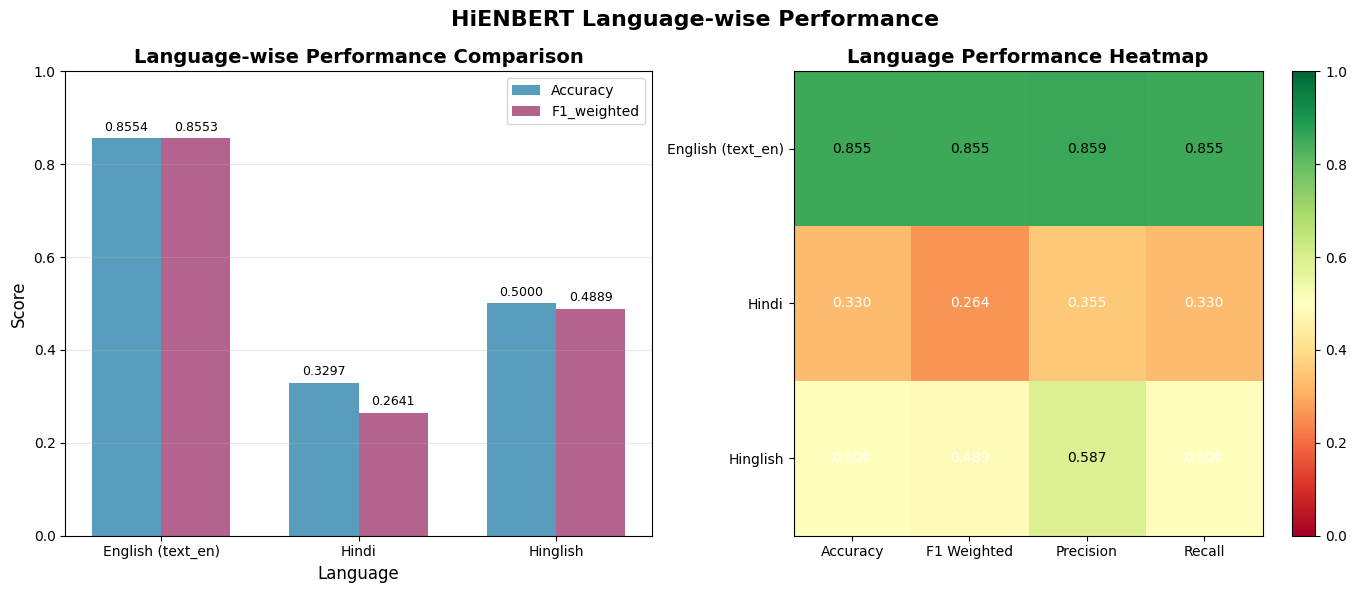


FULL TEST SET EVALUATION



------------------------------------------------------------
PRIMARY CATEGORY METRICS
------------------------------------------------------------
Accuracy: 0.9167
Balanced Accuracy: 0.9146
F1 Macro: 0.9166
F1 Weighted: 0.9164
Precision: 0.9171
Recall: 0.9167

------------------------------------------------------------
SUBCATEGORY METRICS
------------------------------------------------------------
Accuracy: 0.8185
Balanced Accuracy: 0.7952
F1 Macro: 0.8009
F1 Weighted: 0.8189

------------------------------------------------------------
SEVERITY METRICS
------------------------------------------------------------
Accuracy: 0.8067
Balanced Accuracy: 0.7995
F1 Macro: 0.7992
F1 Weighted: 0.8055

GENERATING CONFUSION MATRICES


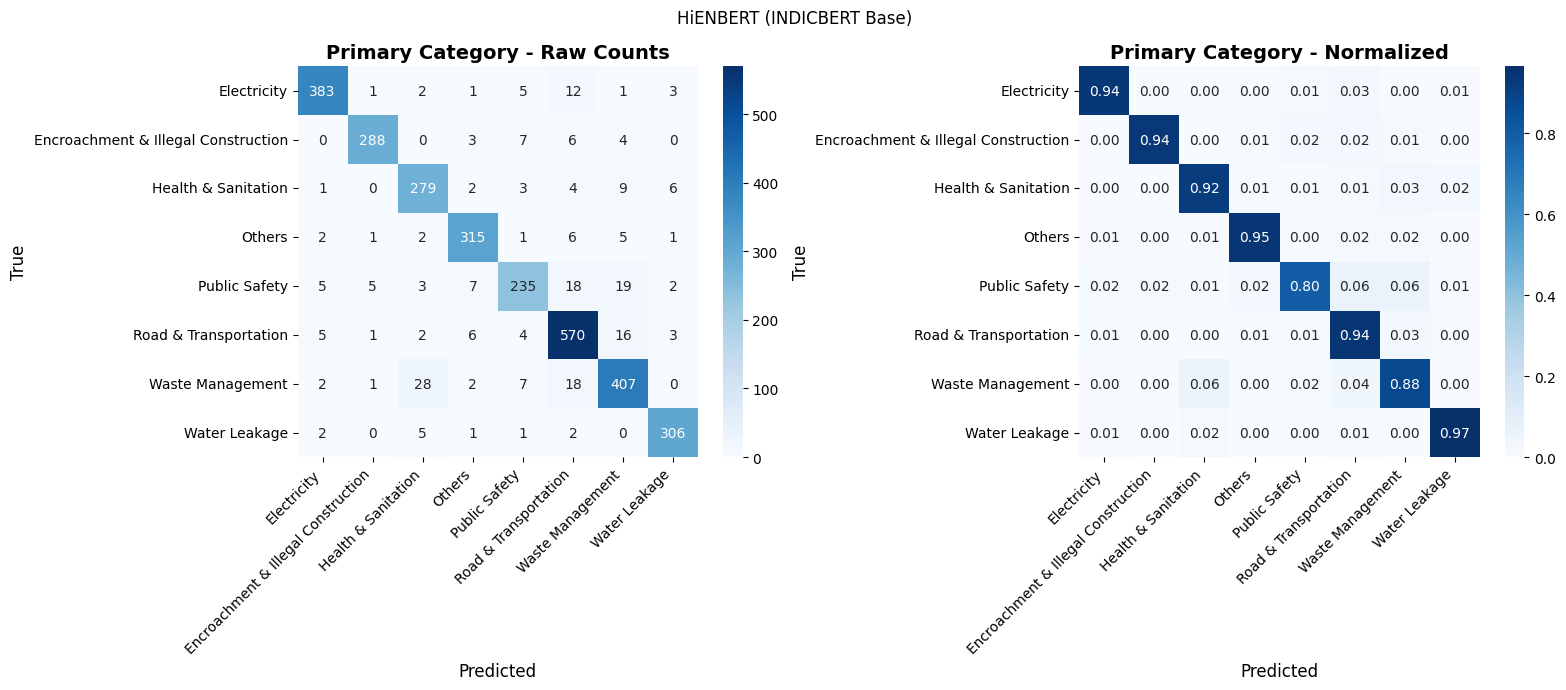

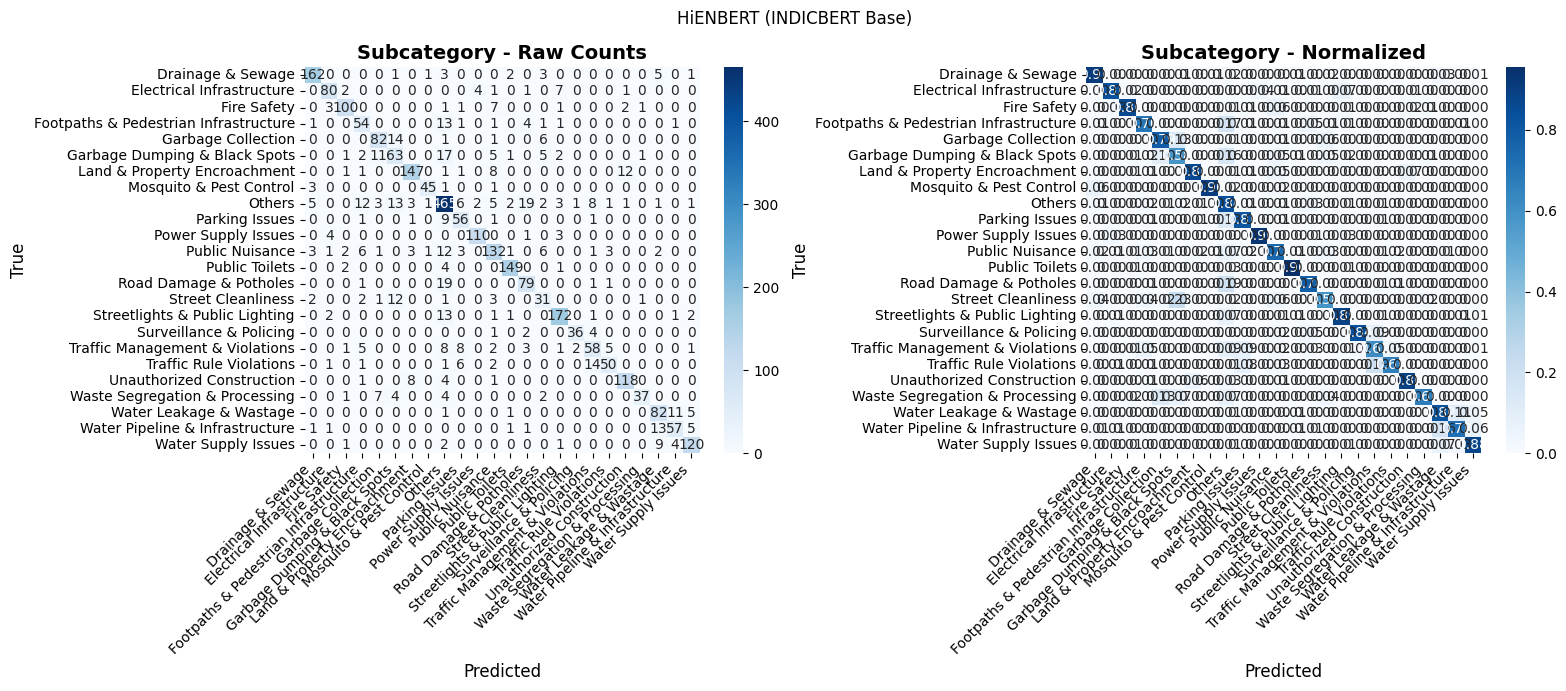

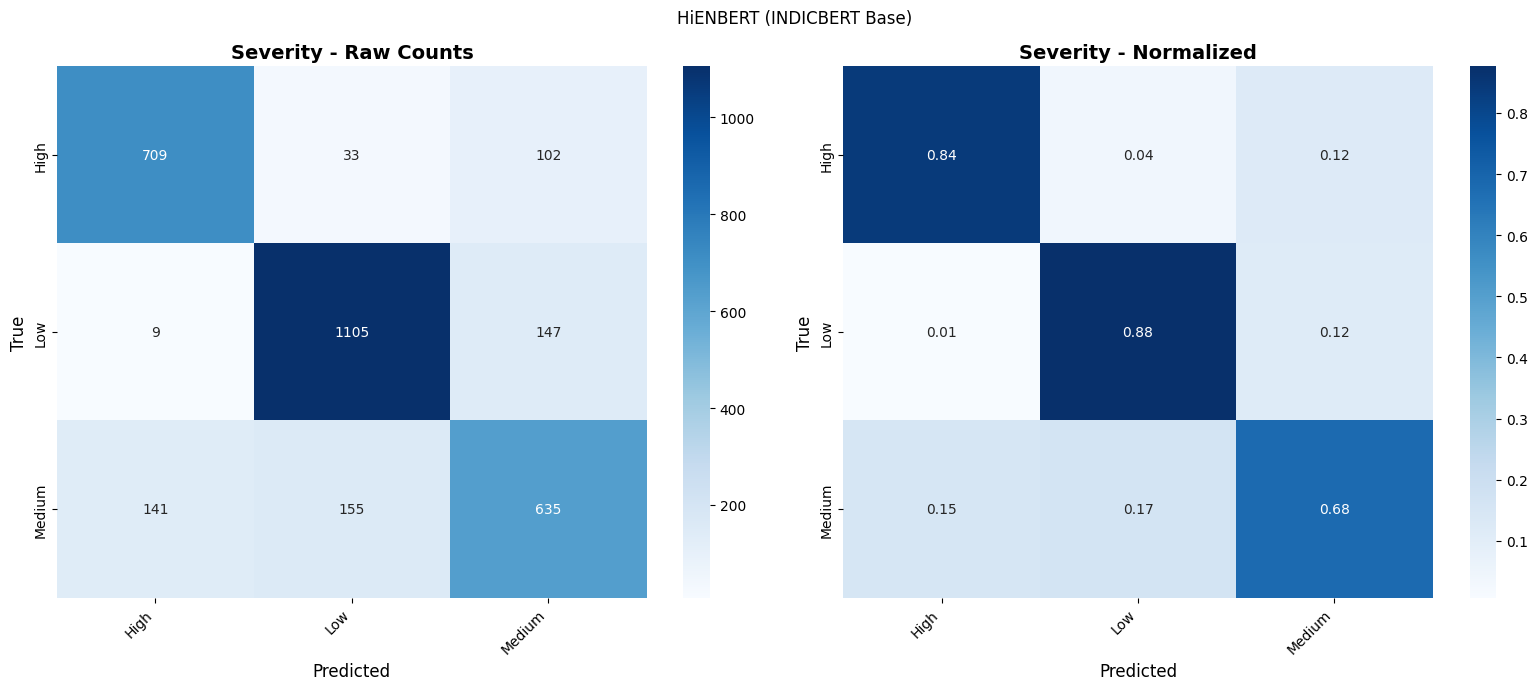


PER-CLASS PERFORMANCE ANALYSIS


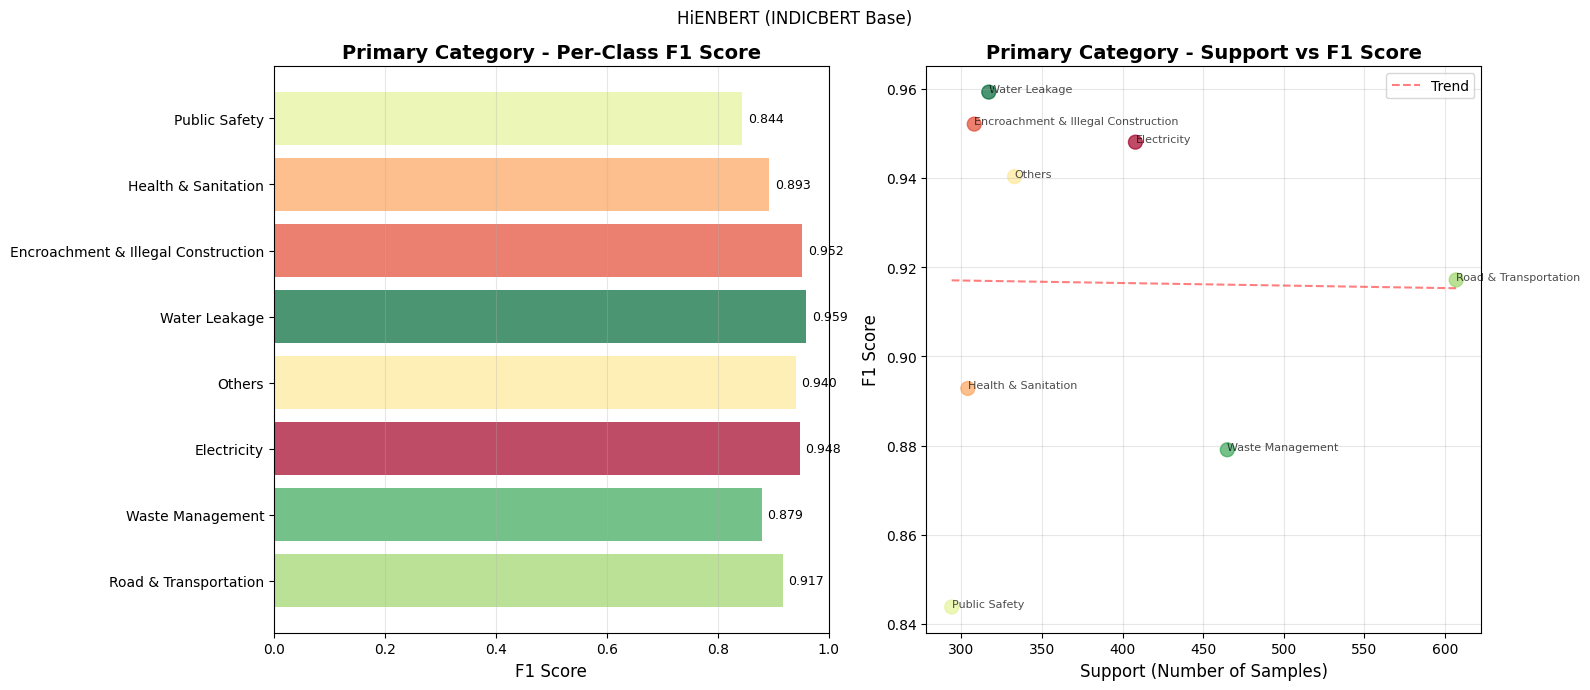

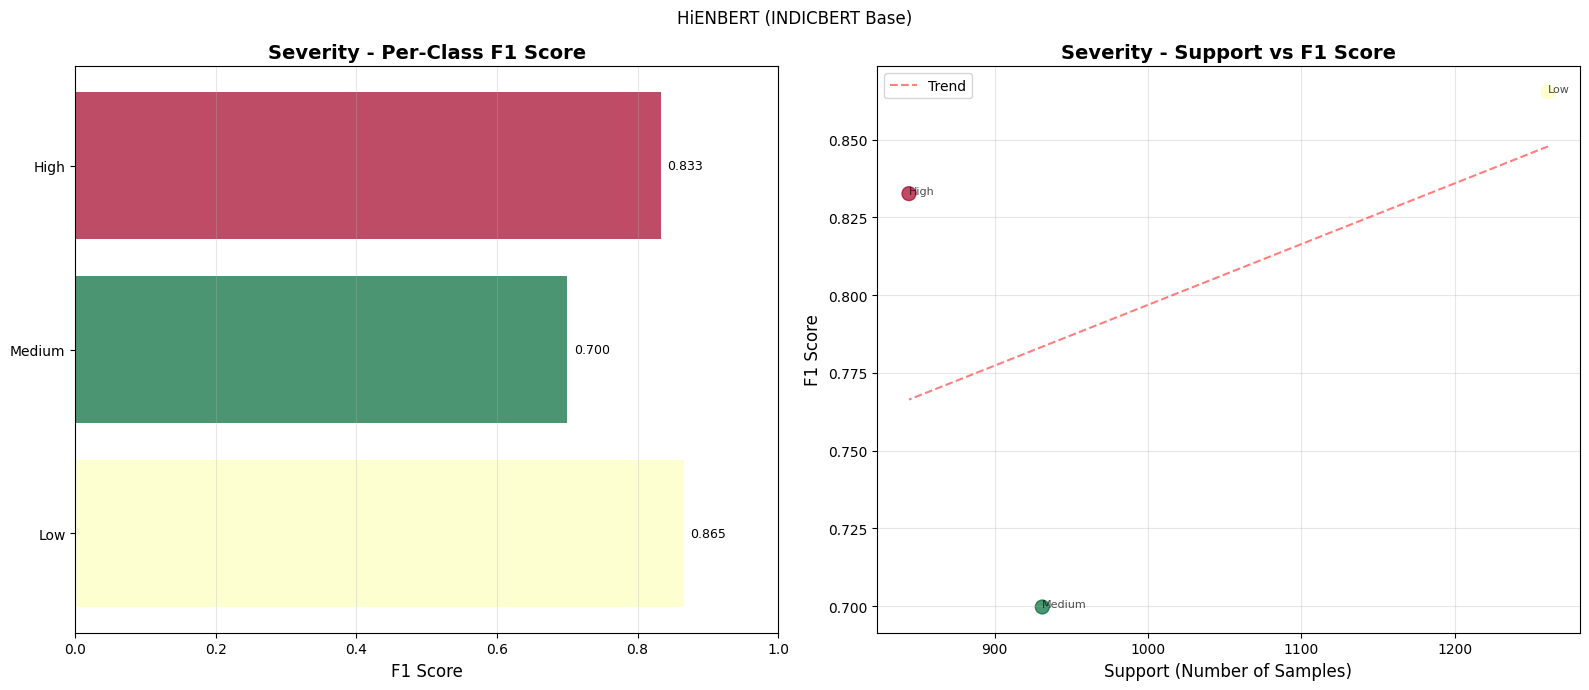


T-SNE EMBEDDING VISUALIZATION
Extracting embeddings for t-SNE...


Extracting embeddings: 100%|██████████| 48/48 [00:17<00:00,  2.80it/s]


Extracted 3036 embeddings of dimension 768
Applying t-SNE...


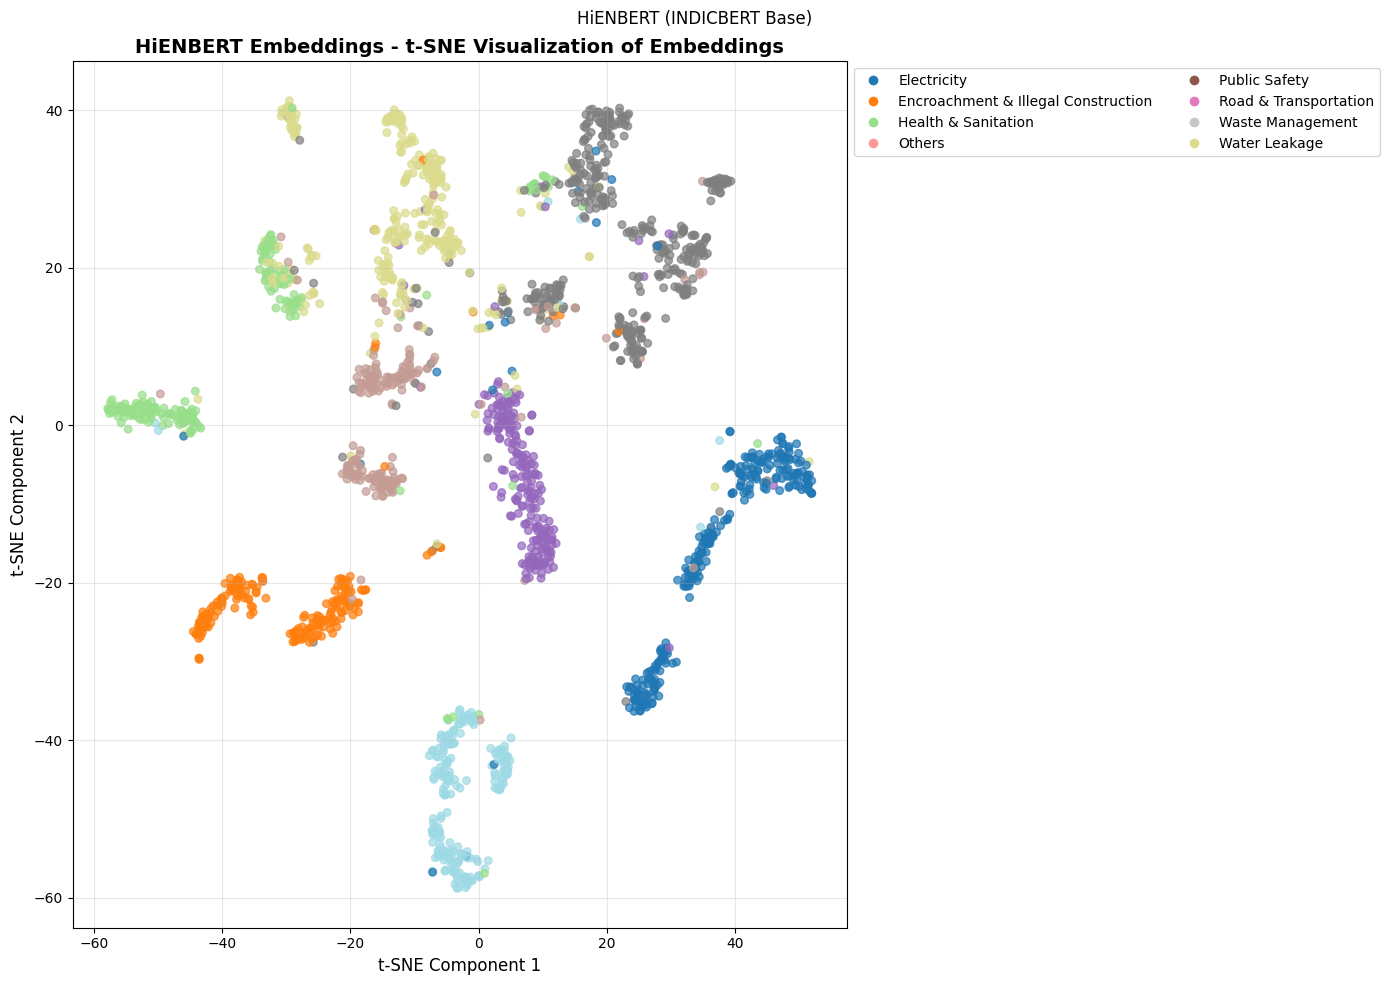


LANGUAGE-SPECIFIC PERFORMANCE VISUALIZATION


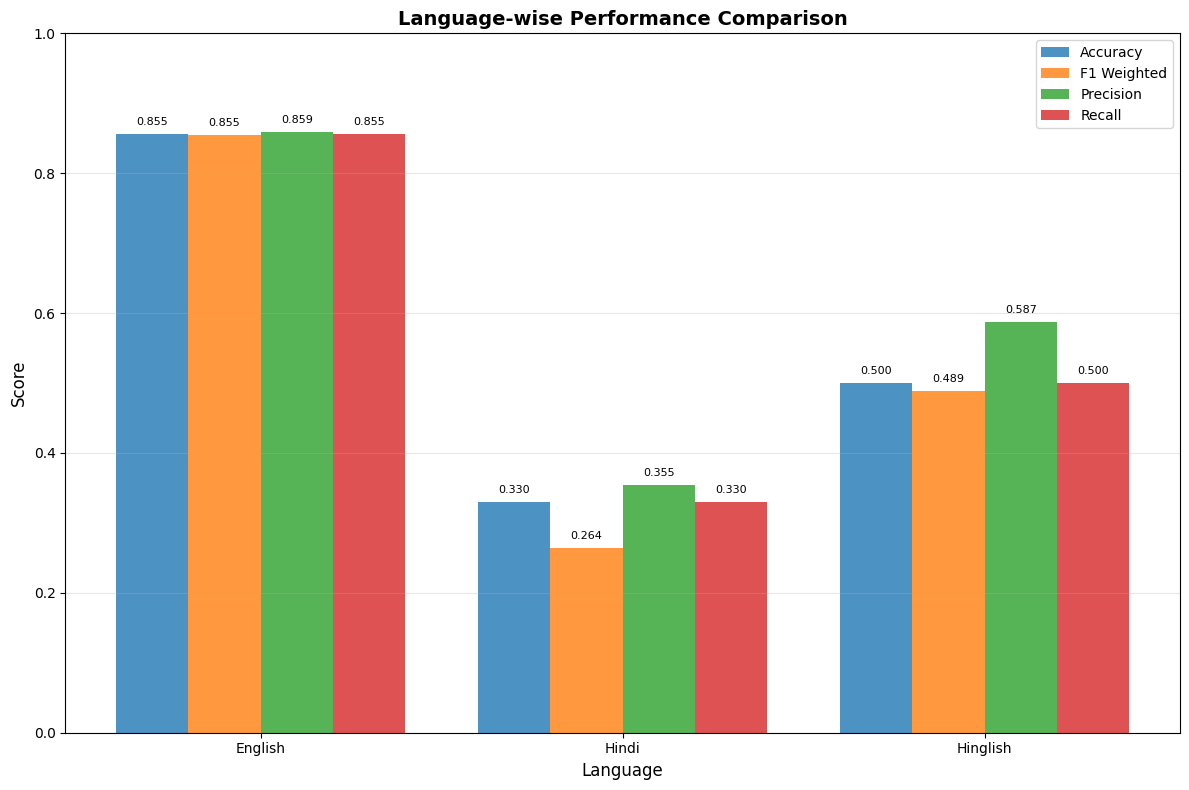


SHAP ANALYSIS

Testing SHAP prediction function...
Prediction shape: (2, 8)
Number of primary classes: 8

Text: There is a large pothole on the main road
Predicted: Road & Transportation
Confidence: 0.8994

Text: Street lights are not working in my area
Predicted: Electricity
Confidence: 0.9887

Creating SHAP Text Explainer...
✓ SHAP Text Explainer created

Global SHAP samples: 50

----------------------------------------------------------------------
COMPUTING GLOBAL SHAP VALUES
----------------------------------------------------------------------
This may take several minutes...


PartitionExplainer explainer: 51it [02:24,  3.06s/it]                        


✓ Global SHAP values computed
✓ Saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\shap_explanations\global_explanations\global_shap_values.pkl

----------------------------------------------------------------------
CALCULATING GLOBAL TOKEN IMPORTANCE
----------------------------------------------------------------------
✓ Saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\shap_explanations\global_explanations\global_token_importance.csv


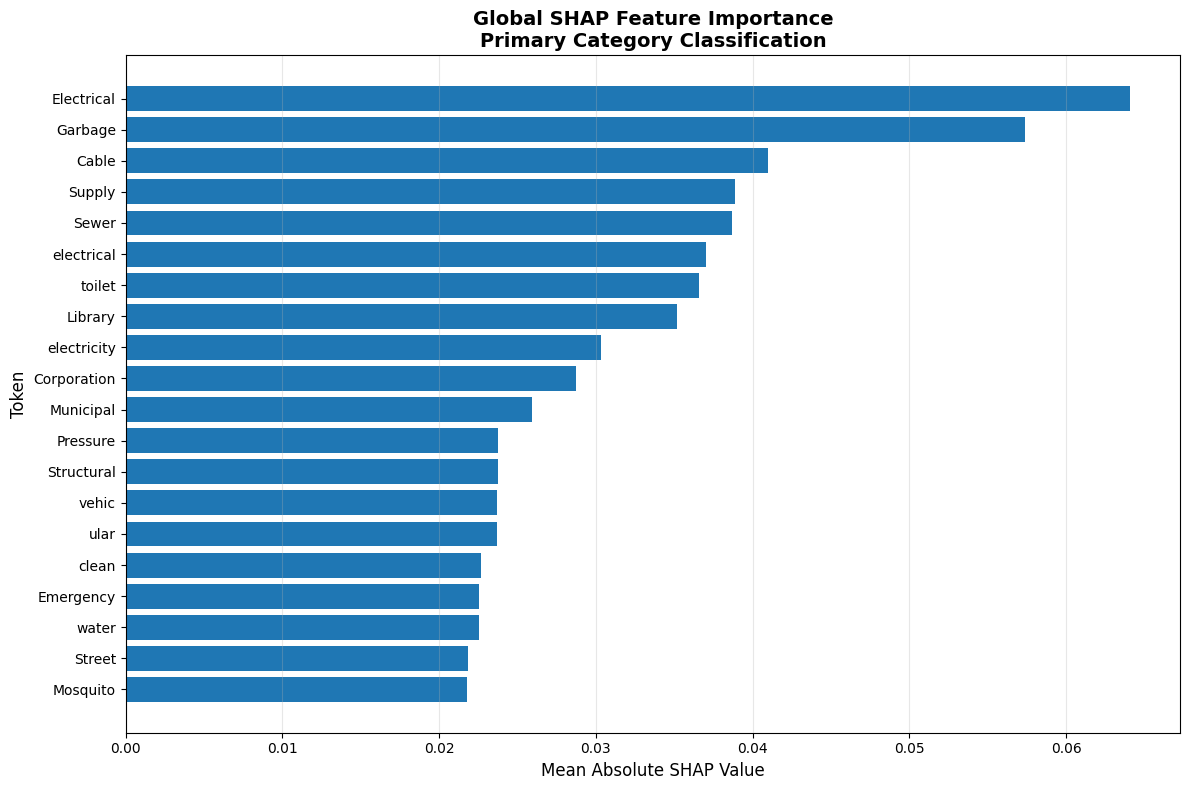

✓ Saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\shap_explanations\global_explanations\global_shap_feature_importance.png

Top Global SHAP Features:
      token  mean_abs_shap  frequency
 Electrical       0.064065          1
    Garbage       0.057392          3
      Cable       0.041008          1
     Supply       0.038846          2
      Sewer       0.038684          1
 electrical       0.037036          1
     toilet       0.036579          1
    Library       0.035146          1
electricity       0.030314          3
Corporation       0.028732          1
  Municipal       0.025918          2
   Pressure       0.023771          1
 Structural       0.023759          1
       ular       0.023713          1
      vehic       0.023713          1
      clean       0.022687          3
  Emergency       0.022572          3
      water       0.022527         18
     Street       0.021864          1
   Mosquito       0.021810          2

LOCAL SHA

PartitionExplainer explainer: 6it [00:11, 11.05s/it]               


✓ Local SHAP values computed
✓ Saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\shap_explanations\local_explanations\local_shap_values.pkl


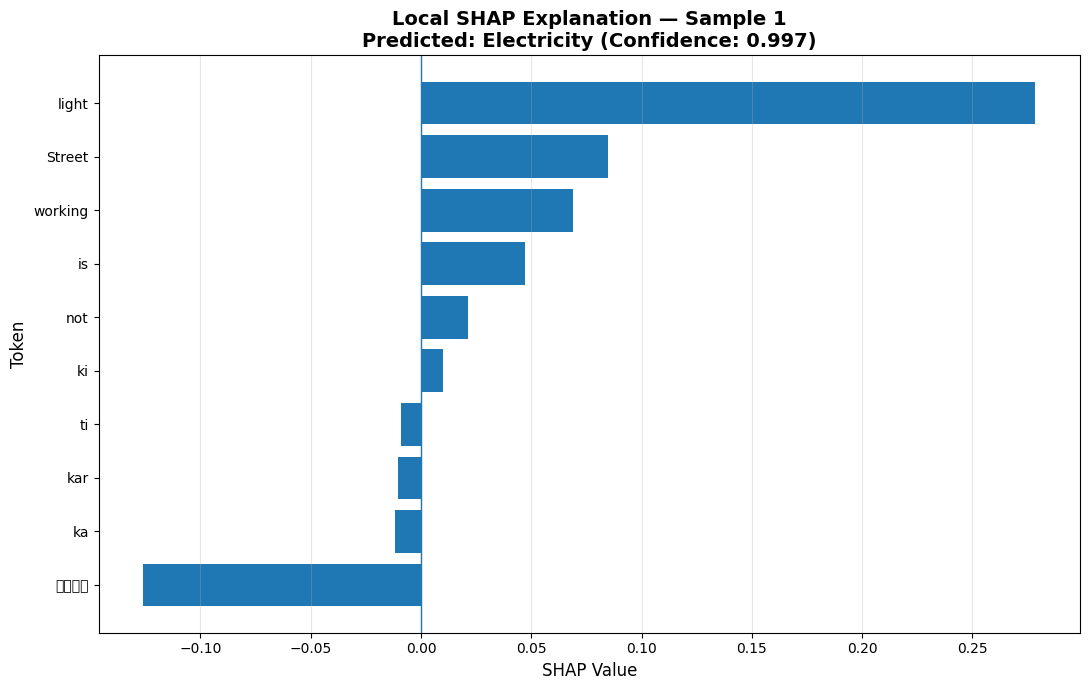

✓ Saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\shap_explanations\local_explanations\local_shap_sample_1.html


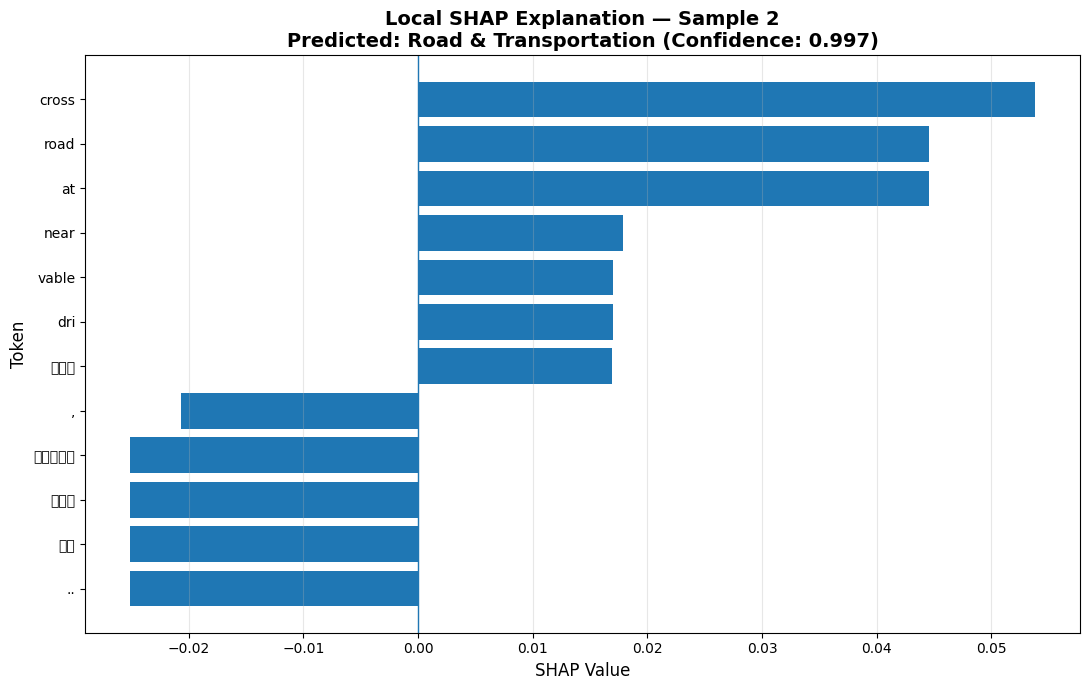

✓ Saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\shap_explanations\local_explanations\local_shap_sample_2.html


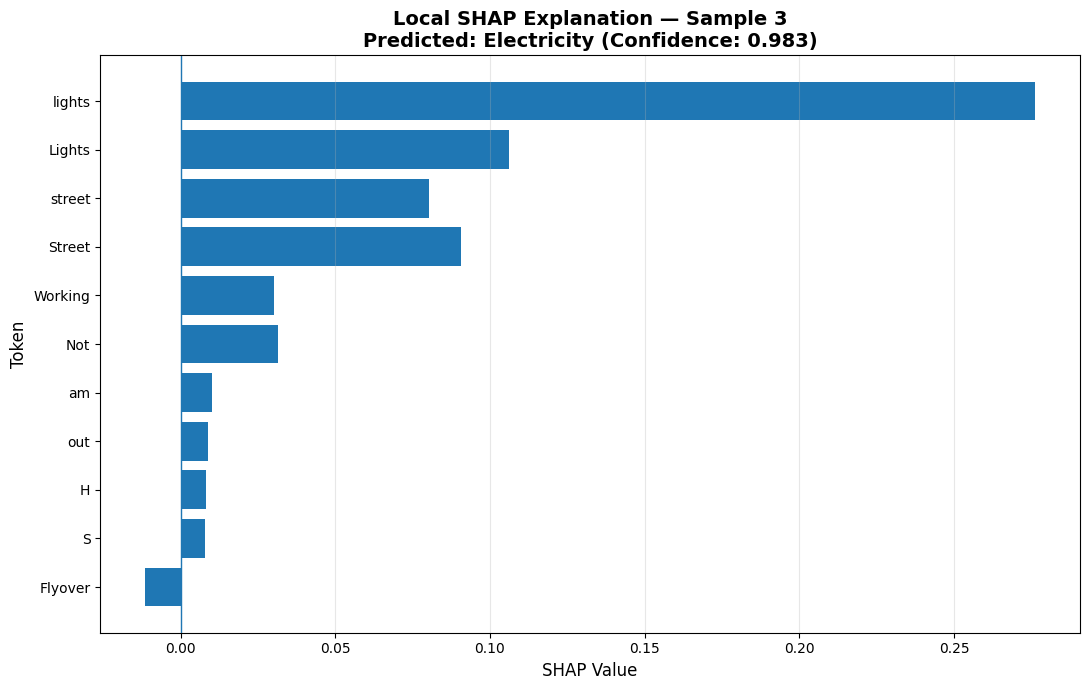

✓ Saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\shap_explanations\local_explanations\local_shap_sample_3.html


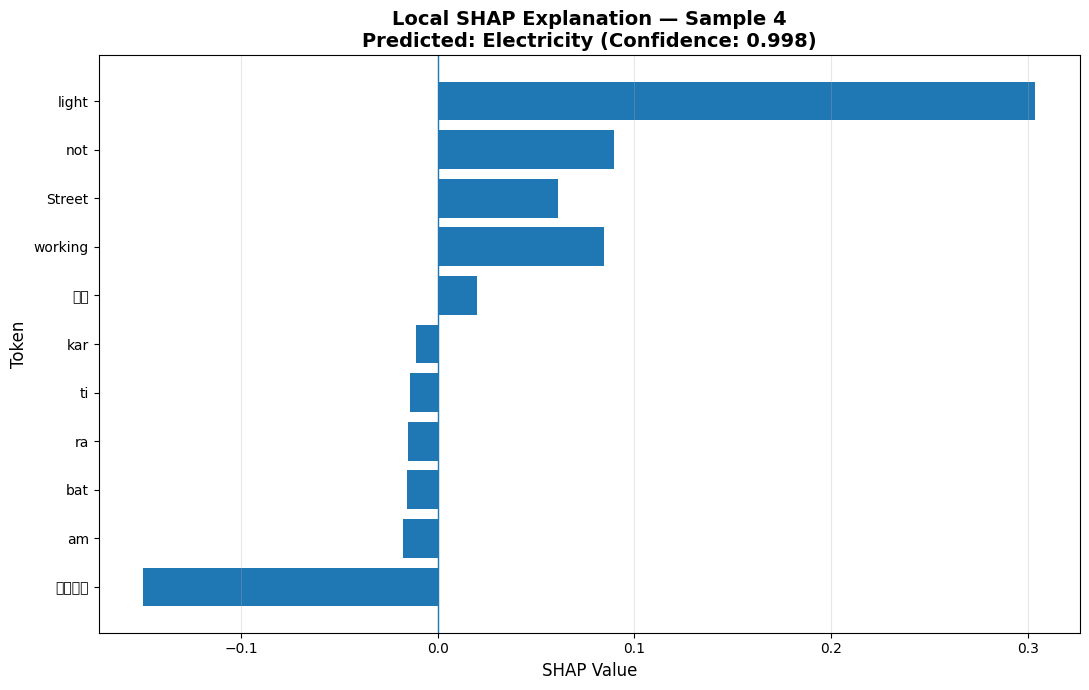

✓ Saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\shap_explanations\local_explanations\local_shap_sample_4.html


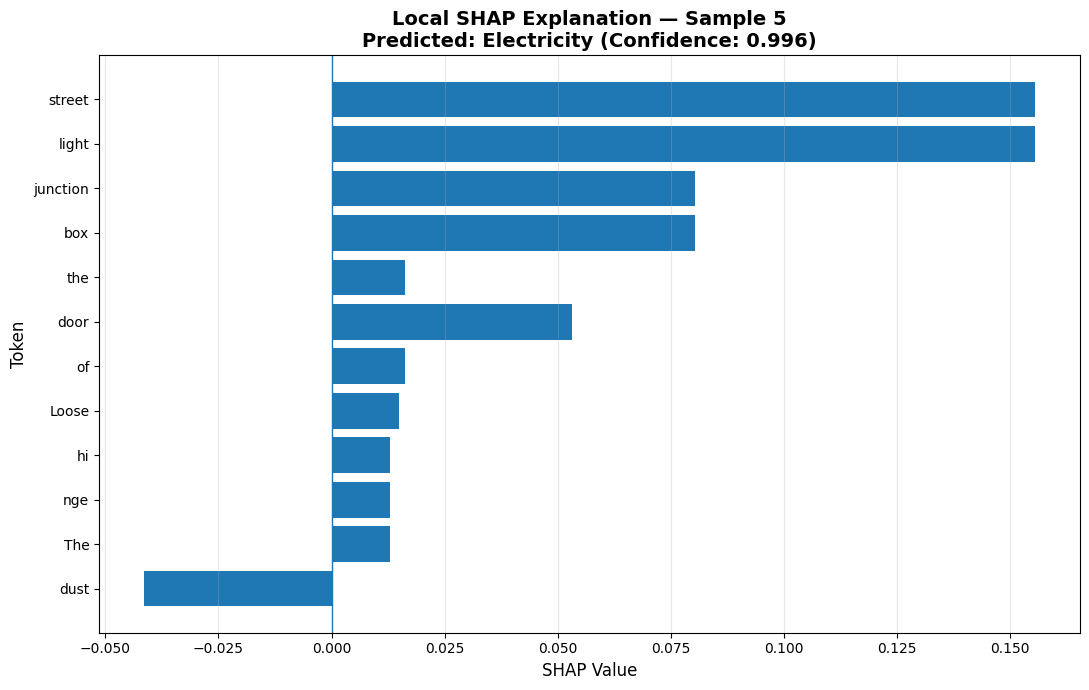

✓ Saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\shap_explanations\local_explanations\local_shap_sample_5.html
✓ Saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\shap_explanations\local_explanations\local_explanation_summary.csv

CLASS-SPECIFIC SHAP ANALYSIS
✓ Class-specific SHAP results saved to:
  C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\shap_explanations\class_specific
✓ Saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\shap_explanations\class_specific\representative_shap_examples.csv
✓ Saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_common_dataset_indic\shap_explanations\shap_metadata.json

SHAP ANALYSIS COMPLETE
Primary classes      : 8
Global samples       : 50
Local samples        : 5
Explainer            : SHAP PartitionExplainer
Task                 : Primary Category

Output directory:
C:\Use

In [ ]:
# ============================================================================
# LOAD TRAINED MODEL AND GENERATE RESULTS
# This script loads the saved model and generates all visualizations
# without retraining
# ============================================================================

import os
import sys
import warnings
warnings.filterwarnings('ignore')
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pickle
import json
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Transformers
from transformers import AutoTokenizer, AutoModel

# Scikit-learn
from sklearn.preprocessing import LabelEncoder
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, balanced_accuracy_score
)

# SHAP for Explainable AI
import shap

# Set random seeds for reproducibility
def set_seed(seed=42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# ============================================================================
# CONFIGURATION
# ============================================================================

class Config:
    """Configuration settings"""
    BASE_MODEL = 'indicbert'
    INDICBERT_PATH = "ai4bharat/indic-bert"
    XLMBERT_PATH = "xlm-roberta-base"
    
    # Project directories
    PROJECT_DIR = os.getcwd()
    
    # Data directory
    DATA_DIR = os.path.join(PROJECT_DIR, "Common_Dataset")
    TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
    DEV_PATH = os.path.join(DATA_DIR, "dev.csv")
    TEST_PATH = os.path.join(DATA_DIR, "test.csv")
    
    # Output directory - use the same as training
    BASE_DIR = os.path.join(PROJECT_DIR, "hienbert_results_common_dataset_indic")
    
    # Subdirectories
    MODEL_DIR = os.path.join(BASE_DIR, "models")
    VISUALIZATION_DIR = os.path.join(BASE_DIR, "visualizations")
    LOG_DIR = os.path.join(BASE_DIR, "logs")
    RESULTS_DIR = os.path.join(BASE_DIR, "results")
    CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints")
    PREDICTION_DIR = os.path.join(BASE_DIR, "predictions")
    EMBEDDING_DIR = os.path.join(BASE_DIR, "embeddings")
    SHAP_DIR = os.path.join(BASE_DIR, "shap_explanations")
    
    # Training parameters
    MAX_LENGTH = 128
    BATCH_SIZE = 32
    
    # Device
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    SEED = 42
    
    # Hugging Face token
    HF_TOKEN = os.getenv("HF_TOKEN")

# Create directories if they don't exist
for dir_path in [
    Config.VISUALIZATION_DIR, Config.RESULTS_DIR, 
    Config.PREDICTION_DIR, Config.EMBEDDING_DIR, Config.SHAP_DIR
]:
    os.makedirs(dir_path, exist_ok=True)

def get_model_path():
    if Config.BASE_MODEL == 'indicbert':
        return Config.INDICBERT_PATH
    elif Config.BASE_MODEL == 'xlm-roberta':
        return Config.XLMBERT_PATH
    else:
        raise ValueError(f"Unsupported base model: {Config.BASE_MODEL}")

print(f"Using output directory: {Config.BASE_DIR}")

# ============================================================================
# LOAD DATA
# ============================================================================

print("\n" + "="*80)
print("LOADING DATA")
print("="*80)

def load_data():
    train_df = pd.read_csv(Config.TRAIN_PATH)
    dev_df = pd.read_csv(Config.DEV_PATH)
    test_df = pd.read_csv(Config.TEST_PATH)
    
    print(f"Train samples: {len(train_df)}")
    print(f"Dev samples: {len(dev_df)}")
    print(f"Test samples: {len(test_df)}")
    print(f"Columns: {train_df.columns.tolist()}")
    
    return train_df, dev_df, test_df

train_df, dev_df, test_df = load_data()

# ============================================================================
# DATA PREPROCESSING
# ============================================================================

print("\n" + "="*80)
print("PREPROCESSING DATA")
print("="*80)

class DataPreprocessor:
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        
        self.column_mapping = {
            'primary_category': 'category_primary',
            'secondary_category': 'category_secondary',
            'Severity': 'severity',
            'Complaint_Title': 'complaint_title',
            'Text_en': 'text_en',
            'Text_hi': 'Hindi',
            'Text_hinglish': 'Hinglish',
            'Sy_No': 'sy_no'
        }
    
    def rename_columns(self, df):
        rename_dict = {k: v for k, v in self.column_mapping.items() if k in df.columns}
        if rename_dict:
            df = df.rename(columns=rename_dict)
        return df
    
    def preprocess_text(self, df):
        df = self.rename_columns(df)
        
        for col in ['complaint_title', 'text_en', 'Hindi', 'Hinglish']:
            if col in df.columns:
                df[col] = df[col].fillna('').astype(str)
        
        text_columns = []
        if 'complaint_title' in df.columns:
            text_columns.append('complaint_title')
        if 'text_en' in df.columns:
            text_columns.append('text_en')
        if 'Hindi' in df.columns:
            text_columns.append('Hindi')
        if 'Hinglish' in df.columns:
            text_columns.append('Hinglish')
        
        if len(text_columns) > 0:
            df["text"] = (
                df[text_columns]
                .agg(" ".join, axis=1)
                .str.replace(r"\s+", " ", regex=True)
                .str.strip()
            )
        else:
            raise ValueError("No text columns found!")
        
        df = df.dropna(subset=["category_primary", "category_secondary", "severity"])
        return df.reset_index(drop=True)
    
    def prepare_labels(self, train_df, dev_df, test_df):
        print("Preparing labels...")
        
        self.le_primary.fit(train_df['category_primary'])
        self.le_subcat.fit(train_df['category_secondary'])
        self.le_severity.fit(train_df['severity'])
        
        print(f"Primary categories: {len(self.le_primary.classes_)}")
        print(f"Subcategories: {len(self.le_subcat.classes_)}")
        print(f"Severity levels: {len(self.le_severity.classes_)}")
        
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["severity"])
            df["sentiment_score"] = 0.0
        
        return train_df, dev_df, test_df
    
    def process_data(self, train_df, dev_df, test_df):
        print("Preprocessing text...")
        train_df = self.preprocess_text(train_df)
        dev_df = self.preprocess_text(dev_df)
        test_df = self.preprocess_text(test_df)
        
        train_df, dev_df, test_df = self.prepare_labels(train_df, dev_df, test_df)
        
        print(f"Final datasets:")
        print(f"  Training: {len(train_df)} samples")
        print(f"  Validation: {len(dev_df)} samples")
        print(f"  Test: {len(test_df)} samples")
        
        return train_df, dev_df, test_df

preprocessor = DataPreprocessor()
train_df, dev_df, test_df = preprocessor.process_data(train_df, dev_df, test_df)

# ============================================================================
# LOAD TOKENIZER AND MODEL
# ============================================================================

print("\n" + "="*80)
print("LOADING TOKENIZER AND MODEL")
print("="*80)

# Load tokenizer
print("Loading tokenizer...")
if Config.BASE_MODEL == 'indicbert':
    tokenizer = AutoTokenizer.from_pretrained(
        get_model_path(),
        token=Config.HF_TOKEN,
        use_fast=False
    )
else:
    tokenizer = AutoTokenizer.from_pretrained(
        get_model_path(),
        token=Config.HF_TOKEN
    )

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Load base model
print("Loading base model...")
base_model = AutoModel.from_pretrained(
    get_model_path(),
    token=Config.HF_TOKEN
)
print(f"Vocabulary size: {tokenizer.vocab_size}")
print(f"Hidden size: {base_model.config.hidden_size}")

# Define model architecture (must match training)
class HiEnBERTModel(nn.Module):
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        
        self.shared_layer = nn.Sequential(
            nn.Linear(hidden_size, hidden_size),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size, n_severity)
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        
        x = self.shared_layer(cls_embedding)
        x = self.dropout(x)
        
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits
    
    def get_embeddings(self, input_ids, attention_mask):
        with torch.no_grad():
            outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
            return outputs.last_hidden_state[:, 0, :]

# Create model with correct dimensions
n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = HiEnBERTModel(
    base_model=base_model,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=0.3
)

# Load saved model
model_path = os.path.join(Config.MODEL_DIR, "hienbert_model.pt")
if os.path.exists(model_path):
    print(f"Loading model from: {model_path}")
    state_dict = torch.load(model_path, map_location=Config.DEVICE)
    model.load_state_dict(state_dict)
    print("✓ Model loaded successfully")
else:
    print(f"WARNING: Model file not found at {model_path}")
    print("Looking for best model...")
    best_model_path = os.path.join(Config.MODEL_DIR, "best_hienberg_model.pt")
    if os.path.exists(best_model_path):
        print(f"Loading best model from: {best_model_path}")
        checkpoint = torch.load(best_model_path, map_location=Config.DEVICE, weights_only=False)
        model.load_state_dict(checkpoint["model_state_dict"])
        print("✓ Best model loaded successfully")
    else:
        print("ERROR: No saved model found. Please train the model first.")

model = model.to(Config.DEVICE)
model.eval()

# ============================================================================
# CREATE DATALOADERS
# ============================================================================

class ComplaintDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=128):
        self.texts = df["text"].astype(str).tolist()
        self.primary = df["primary_label"].tolist()
        self.subcat = df["subcat_label"].tolist()
        self.severity = df["severity_label"].tolist()
        self.sentiment = [0.0] * len(df)
        self.tokenizer = tokenizer
        self.max_length = max_length
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        text = self.texts[idx]
        
        enc = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": torch.tensor(self.primary[idx], dtype=torch.long),
            "subcat": torch.tensor(self.subcat[idx], dtype=torch.long),
            "severity": torch.tensor(self.severity[idx], dtype=torch.long),
            "sentiment": torch.tensor(0.0, dtype=torch.float)
        }

def create_dataloaders(df, tokenizer):
    dataset = ComplaintDataset(df, tokenizer, Config.MAX_LENGTH)
    loader = DataLoader(
        dataset,
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )
    return loader

test_loader = create_dataloaders(test_df, tokenizer)
print(f"Test batches: {len(test_loader)}")

# ============================================================================
# 1. LANGUAGE-WISE PERFORMANCE
# ============================================================================

print("\n" + "="*80)
print("LANGUAGE-WISE PERFORMANCE ANALYSIS")
print("="*80)

def get_language_predictions(model, test_loader, device):
    """Get predictions for each language column separately"""
    model.eval()
    
    languages = ['text_en', 'Hindi', 'Hinglish']
    results = {}
    
    for lang in languages:
        print(f"\nProcessing {lang}...")
        
        # Create dataset with only this language column
        class LangDataset(Dataset):
            def __init__(self, df, tokenizer, lang_col, max_length=128):
                self.texts = df[lang_col].fillna('').astype(str).tolist()
                self.primary = df["primary_label"].tolist()
                self.tokenizer = tokenizer
                self.max_length = max_length
            
            def __len__(self):
                return len(self.texts)
            
            def __getitem__(self, idx):
                text = self.texts[idx]
                enc = self.tokenizer(
                    text,
                    truncation=True,
                    padding="max_length",
                    max_length=self.max_length,
                    return_tensors="pt"
                )
                return {
                    "input_ids": enc["input_ids"].squeeze(0),
                    "attention_mask": enc["attention_mask"].squeeze(0),
                    "primary": torch.tensor(self.primary[idx], dtype=torch.long)
                }
        
        dataset = LangDataset(test_df, tokenizer, lang)
        loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=0)
        
        all_preds = []
        all_labels = []
        
        with torch.no_grad():
            for batch in tqdm(loader, desc=f"Evaluating {lang}", leave=False):
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                
                p1, _, _ = model(input_ids, attention_mask, None)
                preds = torch.argmax(p1, dim=1)
                
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(batch['primary'].cpu().numpy())
        
        results[lang] = {
            'accuracy': accuracy_score(all_labels, all_preds),
            'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
            'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
            'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
            'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0),
            'predictions': all_preds,
            'labels': all_labels
        }
        
        print(f"  {lang}: Accuracy = {results[lang]['accuracy']:.4f}, F1 = {results[lang]['f1_weighted']:.4f}")
    
    return results

# Get language-wise results
lang_results = get_language_predictions(model, test_loader, Config.DEVICE)

# Create language performance plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

languages = ['English (text_en)', 'Hindi', 'Hinglish']
lang_keys = ['text_en', 'Hindi', 'Hinglish']

# Accuracy and F1
metrics = ['accuracy', 'f1_weighted']
colors = ['#2E86AB', '#A23B72', '#F18F01']
x = np.arange(len(languages))
width = 0.35

for i, metric in enumerate(metrics):
    values = [lang_results[k][metric] for k in lang_keys]
    ax = axes[0]
    bars = ax.bar(x + i*width, values, width, label=metric.capitalize(), 
                  color=colors[i], alpha=0.8)
    
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                f'{val:.4f}', ha='center', va='bottom', fontsize=9)

axes[0].set_xlabel('Language', fontsize=12)
axes[0].set_ylabel('Score', fontsize=12)
axes[0].set_title('Language-wise Performance Comparison', fontsize=14, fontweight='bold')
axes[0].set_xticks(x + width/2)
axes[0].set_xticklabels(languages)
axes[0].set_ylim(0, 1)
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Heatmap of language performance
data = []
for lang in lang_keys:
    data.append([
        lang_results[lang]['accuracy'],
        lang_results[lang]['f1_weighted'],
        lang_results[lang]['precision'],
        lang_results[lang]['recall']
    ])

im = axes[1].imshow(data, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)
axes[1].set_xticks(range(4))
axes[1].set_xticklabels(['Accuracy', 'F1 Weighted', 'Precision', 'Recall'])
axes[1].set_yticks(range(3))
axes[1].set_yticklabels(languages)
axes[1].set_title('Language Performance Heatmap', fontsize=14, fontweight='bold')

for i in range(len(languages)):
    for j in range(4):
        axes[1].text(j, i, f'{data[i][j]:.3f}', ha='center', va='center', 
                     color='black' if data[i][j] > 0.5 else 'white', fontsize=10)

plt.colorbar(im, ax=axes[1])

plt.suptitle('HiENBERT Language-wise Performance', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/language_performance.png", dpi=300, bbox_inches='tight')
plt.show()

# ============================================================================
# 2. FULL TEST SET EVALUATION WITH ALL METRICS
# ============================================================================

print("\n" + "="*80)
print("FULL TEST SET EVALUATION")
print("="*80)

def evaluate_full(model, test_loader, device):
    model.eval()
    all_preds = []
    all_labels = []
    all_sev_preds = []
    all_sev_labels = []
    all_subcat_preds = []
    all_subcat_labels = []
    
    with torch.no_grad():
        for batch in tqdm(test_loader, desc="Evaluating", leave=False):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            
            p1, p2, p3 = model(input_ids, attention_mask, None)
            
            # Primary
            preds = torch.argmax(p1, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['primary'].cpu().numpy())
            
            # Subcategory
            sub_preds = torch.argmax(p2, dim=1)
            all_subcat_preds.extend(sub_preds.cpu().numpy())
            all_subcat_labels.extend(batch['subcat'].cpu().numpy())
            
            # Severity
            sev_preds = torch.argmax(p3, dim=1)
            all_sev_preds.extend(sev_preds.cpu().numpy())
            all_sev_labels.extend(batch['severity'].cpu().numpy())
    
    return {
        'primary': {'preds': all_preds, 'labels': all_labels},
        'subcategory': {'preds': all_subcat_preds, 'labels': all_subcat_labels},
        'severity': {'preds': all_sev_preds, 'labels': all_sev_labels}
    }

# Get predictions
all_predictions = evaluate_full(model, test_loader, Config.DEVICE)

# Calculate metrics for each task
def calculate_metrics(preds, labels):
    return {
        'accuracy': accuracy_score(labels, preds),
        'balanced_accuracy': balanced_accuracy_score(labels, preds),
        'f1_macro': f1_score(labels, preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(labels, preds, average='weighted', zero_division=0),
        'precision': precision_score(labels, preds, average='weighted', zero_division=0),
        'recall': recall_score(labels, preds, average='weighted', zero_division=0),
        'classification_report': classification_report(labels, preds, zero_division=0)
    }

primary_metrics = calculate_metrics(all_predictions['primary']['preds'], all_predictions['primary']['labels'])
subcat_metrics = calculate_metrics(all_predictions['subcategory']['preds'], all_predictions['subcategory']['labels'])
severity_metrics = calculate_metrics(all_predictions['severity']['preds'], all_predictions['severity']['labels'])

print("\n" + "-"*60)
print("PRIMARY CATEGORY METRICS")
print("-"*60)
print(f"Accuracy: {primary_metrics['accuracy']:.4f}")
print(f"Balanced Accuracy: {primary_metrics['balanced_accuracy']:.4f}")
print(f"F1 Macro: {primary_metrics['f1_macro']:.4f}")
print(f"F1 Weighted: {primary_metrics['f1_weighted']:.4f}")
print(f"Precision: {primary_metrics['precision']:.4f}")
print(f"Recall: {primary_metrics['recall']:.4f}")

print("\n" + "-"*60)
print("SUBCATEGORY METRICS")
print("-"*60)
print(f"Accuracy: {subcat_metrics['accuracy']:.4f}")
print(f"Balanced Accuracy: {subcat_metrics['balanced_accuracy']:.4f}")
print(f"F1 Macro: {subcat_metrics['f1_macro']:.4f}")
print(f"F1 Weighted: {subcat_metrics['f1_weighted']:.4f}")

print("\n" + "-"*60)
print("SEVERITY METRICS")
print("-"*60)
print(f"Accuracy: {severity_metrics['accuracy']:.4f}")
print(f"Balanced Accuracy: {severity_metrics['balanced_accuracy']:.4f}")
print(f"F1 Macro: {severity_metrics['f1_macro']:.4f}")
print(f"F1 Weighted: {severity_metrics['f1_weighted']:.4f}")

# ============================================================================
# 3. CONFUSION MATRICES
# ============================================================================

print("\n" + "="*80)
print("GENERATING CONFUSION MATRICES")
print("="*80)

def plot_confusion_matrix(y_true, y_pred, class_names, title, save_path=None):
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_normalized = np.nan_to_num(cm_normalized)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    # Raw counts
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[0])
    axes[0].set_title(f'{title} - Raw Counts', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Predicted', fontsize=12)
    axes[0].set_ylabel('True', fontsize=12)
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
    
    # Normalized
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[1])
    axes[1].set_title(f'{title} - Normalized', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Predicted', fontsize=12)
    axes[1].set_ylabel('True', fontsize=12)
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
    
    plt.suptitle(f'HiENBERT ({Config.BASE_MODEL.upper()} Base)', fontsize=12)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Primary confusion matrix
primary_class_names = preprocessor.le_primary.classes_
plot_confusion_matrix(
    all_predictions['primary']['labels'],
    all_predictions['primary']['preds'],
    primary_class_names,
    'Primary Category',
    save_path=f"{Config.VISUALIZATION_DIR}/confusion_matrix_primary_loaded.png"
)

# Subcategory confusion matrix
subcat_class_names = preprocessor.le_subcat.classes_
plot_confusion_matrix(
    all_predictions['subcategory']['labels'],
    all_predictions['subcategory']['preds'],
    subcat_class_names,
    'Subcategory',
    save_path=f"{Config.VISUALIZATION_DIR}/confusion_matrix_subcategory_loaded.png"
)

# Severity confusion matrix
severity_class_names = preprocessor.le_severity.classes_
plot_confusion_matrix(
    all_predictions['severity']['labels'],
    all_predictions['severity']['preds'],
    severity_class_names,
    'Severity',
    save_path=f"{Config.VISUALIZATION_DIR}/confusion_matrix_severity_loaded.png"
)

# ============================================================================
# 4. PER-CLASS PERFORMANCE
# ============================================================================

print("\n" + "="*80)
print("PER-CLASS PERFORMANCE ANALYSIS")
print("="*80)

def plot_per_class_performance(y_true, y_pred, class_names, title, save_path=None):
    from sklearn.metrics import precision_recall_fscore_support
    
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, average=None, zero_division=0
    )
    
    sorted_indices = np.argsort(support)[::-1]
    class_names_sorted = [class_names[i] for i in sorted_indices]
    precision_sorted = [precision[i] for i in sorted_indices]
    recall_sorted = [recall[i] for i in sorted_indices]
    f1_sorted = [f1[i] for i in sorted_indices]
    support_sorted = [support[i] for i in sorted_indices]
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    # F1 scores
    colors = plt.cm.RdYlGn(np.linspace(0, 1, len(class_names)))[sorted_indices]
    bars = axes[0].barh(range(len(class_names)), f1_sorted, color=colors, alpha=0.7)
    axes[0].set_yticks(range(len(class_names)))
    axes[0].set_yticklabels(class_names_sorted, fontsize=10)
    axes[0].set_xlabel('F1 Score', fontsize=12)
    axes[0].set_title(f'{title} - Per-Class F1 Score', fontsize=14, fontweight='bold')
    axes[0].set_xlim(0, 1)
    axes[0].grid(True, alpha=0.3, axis='x')
    
    for bar, val in zip(bars, f1_sorted):
        axes[0].text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                    f'{val:.3f}', va='center', fontsize=9)
    
    # Support vs F1 scatter
    axes[1].scatter(support_sorted, f1_sorted, alpha=0.7, s=100, c=colors)
    axes[1].set_xlabel('Support (Number of Samples)', fontsize=12)
    axes[1].set_ylabel('F1 Score', fontsize=12)
    axes[1].set_title(f'{title} - Support vs F1 Score', fontsize=14, fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    
    try:
        z = np.polyfit(support_sorted, f1_sorted, 1)
        p = np.poly1d(z)
        axes[1].plot(support_sorted, p(support_sorted), "r--", alpha=0.5, label='Trend')
    except:
        pass
    
    for i, (x, y, name) in enumerate(zip(support_sorted, f1_sorted, class_names_sorted)):
        axes[1].annotate(name, (x, y), fontsize=8, alpha=0.7)
    axes[1].legend()
    
    plt.suptitle(f'HiENBERT ({Config.BASE_MODEL.upper()} Base)', fontsize=12)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Per-class performance for primary category
plot_per_class_performance(
    all_predictions['primary']['labels'],
    all_predictions['primary']['preds'],
    primary_class_names,
    'Primary Category',
    save_path=f"{Config.VISUALIZATION_DIR}/per_class_performance_loaded.png"
)

# Per-class performance for severity
plot_per_class_performance(
    all_predictions['severity']['labels'],
    all_predictions['severity']['preds'],
    severity_class_names,
    'Severity',
    save_path=f"{Config.VISUALIZATION_DIR}/severity_per_class_performance_loaded.png"
)

# ============================================================================
# 5. T-SNE VISUALIZATION
# ============================================================================

print("\n" + "="*80)
print("T-SNE EMBEDDING VISUALIZATION")
print("="*80)

def plot_tsne_embeddings(model, test_loader, class_names, device, title, save_path=None):
    print("Extracting embeddings for t-SNE...")
    
    model.eval()
    embeddings = []
    labels = []
    
    with torch.no_grad():
        for batch in tqdm(test_loader, desc="Extracting embeddings"):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            
            # Get embeddings
            outputs = model.base(input_ids=input_ids, attention_mask=attention_mask)
            cls_embedding = outputs.last_hidden_state[:, 0, :]
            embeddings.append(cls_embedding.cpu().numpy())
            labels.extend(batch['primary'].cpu().numpy())
    
    embeddings = np.vstack(embeddings)
    labels = np.array(labels)
    
    print(f"Extracted {embeddings.shape[0]} embeddings of dimension {embeddings.shape[1]}")
    
    # Sample if too many points
    if len(embeddings) > 2000:
        idx = np.random.choice(len(embeddings), 2000, replace=False)
        embeddings = embeddings[idx]
        labels = labels[idx]
    
    # Apply t-SNE
    print("Applying t-SNE...")
    tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000, verbose=0)
    embeddings_2d = tsne.fit_transform(embeddings)
    
    # Create visualization
    fig, ax = plt.subplots(figsize=(14, 10))
    
    scatter = ax.scatter(
        embeddings_2d[:, 0], embeddings_2d[:, 1],
        c=labels, cmap='tab20', alpha=0.7, s=30
    )
    
    ax.set_xlabel('t-SNE Component 1', fontsize=12)
    ax.set_ylabel('t-SNE Component 2', fontsize=12)
    ax.set_title(f'{title} - t-SNE Visualization of Embeddings', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    
    # Add legend
    legend_elements = []
    for i, name in enumerate(class_names):
        if i < len(plt.cm.tab20.colors):
            legend_elements.append(
                plt.Line2D([0], [0], marker='o', color='w',
                          markerfacecolor=plt.cm.tab20(i/len(class_names)),
                          label=name, markersize=8)
            )
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1), ncol=2)
    
    plt.suptitle(f'HiENBERT ({Config.BASE_MODEL.upper()} Base)', fontsize=12)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    return embeddings_2d

# Generate t-SNE visualization
try:
    tsne_embeddings = plot_tsne_embeddings(
        model, test_loader, primary_class_names, Config.DEVICE,
        'HiENBERT Embeddings',
        save_path=f"{Config.VISUALIZATION_DIR}/tsne_embeddings_loaded.png"
    )
except Exception as e:
    print(f"Warning: t-SNE visualization failed: {e}")

# ============================================================================
# 6. LANGUAGE-SPECIFIC PERFORMANCE VISUALIZATION
# ============================================================================

print("\n" + "="*80)
print("LANGUAGE-SPECIFIC PERFORMANCE VISUALIZATION")
print("="*80)

# Create a comprehensive language performance comparison
fig, ax = plt.subplots(figsize=(12, 8))

languages = ['English', 'Hindi', 'Hinglish']
lang_keys = ['text_en', 'Hindi', 'Hinglish']

metrics = ['accuracy', 'f1_weighted', 'precision', 'recall']
metric_labels = ['Accuracy', 'F1 Weighted', 'Precision', 'Recall']

x = np.arange(len(languages))
width = 0.2

for i, (metric, label) in enumerate(zip(metrics, metric_labels)):
    values = [lang_results[k][metric] for k in lang_keys]
    bars = ax.bar(x + i*width, values, width, label=label, alpha=0.8)
    
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xlabel('Language', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Language-wise Performance Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(languages)
ax.set_ylim(0, 1)
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/language_performance_detailed.png", dpi=300, bbox_inches='tight')
plt.show()

# ============================================================================
# 7. SHAP ANALYSIS — EXPLAINABLE CIVIC DECISION SUPPORT
# ============================================================================

print("\n" + "=" * 80)
print("SHAP ANALYSIS")
print("=" * 80)

import re
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap


# ============================================================================
# SHAP CONFIGURATION
# ============================================================================

SHAP_LOCAL_SAMPLES = 5
SHAP_GLOBAL_SAMPLES = 50

# Number of tokens shown in local visualization
TOP_LOCAL_TOKENS = 15

# Number of tokens shown in global visualization
TOP_GLOBAL_TOKENS = 20

# Number of examples stored for each predicted class
EXAMPLES_PER_CLASS = 5


# ============================================================================
# CREATE SHAP OUTPUT DIRECTORIES
# ============================================================================

SHAP_LOCAL_DIR = os.path.join(
    Config.SHAP_DIR,
    "local_explanations"
)

SHAP_GLOBAL_DIR = os.path.join(
    Config.SHAP_DIR,
    "global_explanations"
)

SHAP_CLASS_DIR = os.path.join(
    Config.SHAP_DIR,
    "class_specific"
)

os.makedirs(SHAP_LOCAL_DIR, exist_ok=True)
os.makedirs(SHAP_GLOBAL_DIR, exist_ok=True)
os.makedirs(SHAP_CLASS_DIR, exist_ok=True)


# ============================================================================
# 7.1 SHAP MODEL PREDICTION FUNCTION
# ============================================================================

def shap_model_predict(texts):
    """
    SHAP-compatible prediction function.

    Input:
        List of complaint texts.

    Output:
        Probability distribution over all primary categories.
    """

    model.eval()

    if isinstance(texts, str):
        texts = [texts]

    texts = [
        str(text)
        for text in texts
    ]

    encodings = tokenizer(
        texts,
        truncation=True,
        padding=True,
        max_length=Config.MAX_LENGTH,
        return_tensors="pt"
    )

    input_ids = encodings[
        "input_ids"
    ].to(Config.DEVICE)

    attention_mask = encodings[
        "attention_mask"
    ].to(Config.DEVICE)

    with torch.no_grad():

        primary_logits, _, _ = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            sentiment=None
        )

        probabilities = torch.softmax(
            primary_logits,
            dim=1
        )

    return probabilities.cpu().numpy()


# ============================================================================
# 7.2 VERIFY MODEL PREDICTIONS
# ============================================================================

print("\nTesting SHAP prediction function...")

verification_texts = [
    "There is a large pothole on the main road",
    "Street lights are not working in my area"
]

verification_predictions = shap_model_predict(
    verification_texts
)

print(
    f"Prediction shape: "
    f"{verification_predictions.shape}"
)

print(
    f"Number of primary classes: "
    f"{len(primary_class_names)}"
)

for i, text in enumerate(
    verification_texts
):

    predicted_idx = np.argmax(
        verification_predictions[i]
    )

    predicted_class = (
        primary_class_names[
            predicted_idx
        ]
    )

    confidence = (
        verification_predictions[i][
            predicted_idx
        ]
    )

    print(f"\nText: {text}")
    print(f"Predicted: {predicted_class}")
    print(f"Confidence: {confidence:.4f}")


# ============================================================================
# 7.3 CREATE SHAP TEXT EXPLAINER
# ============================================================================

print("\nCreating SHAP Text Explainer...")

masker = shap.maskers.Text(
    tokenizer
)

explainer = shap.Explainer(
    shap_model_predict,
    masker
)

print("✓ SHAP Text Explainer created")


# ============================================================================
# 7.4 SELECT TEST DATA FOR SHAP
# ============================================================================
#
# IMPORTANT:
#
# Local explanation:
#     A few individual complaints.
#
# Global explanation:
#     Representative sample from TEST SET.
#
# We do NOT claim that 50 samples represent the mathematical
# explanation of every sample in the entire dataset.
#
# For an FYP, this is a practical global SHAP analysis.
# ============================================================================

shap_df = test_df.copy()

# ---------------------------------------------------------
# Global SHAP sample
# ---------------------------------------------------------

global_n = min(
    SHAP_GLOBAL_SAMPLES,
    len(shap_df)
)

global_df = (
    shap_df
    .sample(
        n=global_n,
        random_state=Config.SEED
    )
    .reset_index(drop=True)
)

global_texts = (
    global_df["text"]
    .fillna("")
    .astype(str)
    .tolist()
)

print(
    f"\nGlobal SHAP samples: "
    f"{len(global_texts)}"
)


# ============================================================================
# 7.5 COMPUTE GLOBAL SHAP VALUES
# ============================================================================

print("\n" + "-" * 70)
print("COMPUTING GLOBAL SHAP VALUES")
print("-" * 70)

print(
    "This may take several minutes..."
)

global_shap_values = explainer(
    global_texts
)

print(
    "✓ Global SHAP values computed"
)


# ============================================================================
# SAVE GLOBAL SHAP VALUES
# ============================================================================

global_shap_path = os.path.join(
    SHAP_GLOBAL_DIR,
    "global_shap_values.pkl"
)

with open(
    global_shap_path,
    "wb"
) as f:

    pickle.dump(
        global_shap_values,
        f
    )

print(
    f"✓ Saved: {global_shap_path}"
)


# ============================================================================
# 7.6 FUNCTION TO EXTRACT CLASS-SPECIFIC SHAP VALUES
# ============================================================================

def get_class_shap_values(
    shap_explanation,
    class_idx
):
    """
    Extract SHAP values for one output class.

    Handles both common SHAP output formats.
    """

    values = shap_explanation.values

    # ---------------------------------------------------------
    # Single output
    # ---------------------------------------------------------

    if values.ndim == 1:

        return values

    # ---------------------------------------------------------
    # Token x class
    # ---------------------------------------------------------

    if values.ndim == 2:

        if class_idx < values.shape[1]:

            return values[:, class_idx]

    # ---------------------------------------------------------
    # Fallback
    # ---------------------------------------------------------

    return values


# ============================================================================
# 7.7 GLOBAL TOKEN IMPORTANCE
# ============================================================================

print("\n" + "-" * 70)
print("CALCULATING GLOBAL TOKEN IMPORTANCE")
print("-" * 70)

global_token_scores = {}

for sample_idx in range(
    len(global_shap_values)
):

    sample_values = (
        global_shap_values[
            sample_idx
        ]
    )

    tokens = sample_values.data
    values = sample_values.values

    # ---------------------------------------------------------
    # For multiclass classification:
    #
    # mean absolute SHAP value across classes
    # ---------------------------------------------------------

    if values.ndim == 2:

        token_scores = np.mean(
            np.abs(values),
            axis=1
        )

    else:

        token_scores = np.abs(
            values
        )

    for token, score in zip(
        tokens,
        token_scores
    ):

        token = str(token).strip()

        # Remove empty tokens
        if not token:
            continue

        # Ignore common special tokens
        if token in [
            "[CLS]",
            "[SEP]",
            "[PAD]"
        ]:
            continue

        if token not in global_token_scores:

            global_token_scores[
                token
            ] = []

        global_token_scores[
            token
        ].append(
            float(score)
        )


# ============================================================================
# CALCULATE MEAN GLOBAL IMPORTANCE
# ============================================================================

global_importance = []

for token, scores in (
    global_token_scores.items()
):

    global_importance.append({

        "token": token,

        "mean_abs_shap":
            float(np.mean(scores)),

        "frequency":
            len(scores)
    })


global_importance_df = (
    pd.DataFrame(
        global_importance
    )
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================================
# SAVE GLOBAL IMPORTANCE CSV
# ============================================================================

global_csv_path = os.path.join(
    SHAP_GLOBAL_DIR,
    "global_token_importance.csv"
)

global_importance_df.to_csv(
    global_csv_path,
    index=False,
    encoding="utf-8"
)

print(
    f"✓ Saved: {global_csv_path}"
)


# ============================================================================
# 7.8 GLOBAL SHAP FEATURE IMPORTANCE VISUALIZATION
# ============================================================================
#
# This corresponds to:
#
# GLOBAL EXPLANATION
# Feature Importance Ranking
#
# in your framework.
# ============================================================================

top_global = (
    global_importance_df
    .head(TOP_GLOBAL_TOKENS)
    .sort_values(
        "mean_abs_shap"
    )
)

plt.figure(
    figsize=(12, 8)
)

plt.barh(
    top_global["token"],
    top_global["mean_abs_shap"]
)

plt.xlabel(
    "Mean Absolute SHAP Value",
    fontsize=12
)

plt.ylabel(
    "Token",
    fontsize=12
)

plt.title(
    "Global SHAP Feature Importance\n"
    "Primary Category Classification",
    fontsize=14,
    fontweight="bold"
)

plt.grid(
    True,
    axis="x",
    alpha=0.3
)

plt.tight_layout()

global_plot_path = os.path.join(
    SHAP_GLOBAL_DIR,
    "global_shap_feature_importance.png"
)

plt.savefig(
    global_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"✓ Saved: {global_plot_path}"
)


# ============================================================================
# 7.9 GLOBAL SHAP SUMMARY TABLE
# ============================================================================

print("\nTop Global SHAP Features:")
print(
    global_importance_df
    .head(TOP_GLOBAL_TOKENS)
    .to_string(index=False)
)


# ============================================================================
# 7.10 LOCAL SHAP ANALYSIS
# ============================================================================
#
# Local explanation:
#
# One complaint
#       ↓
# Predicted class
#       ↓
# Token contributions
#
# Positive value:
#     pushes prediction toward the class
#
# Negative value:
#     pushes prediction away from the class
# ============================================================================

print("\n" + "=" * 80)
print("LOCAL SHAP ANALYSIS")
print("=" * 80)


# ============================================================================
# SELECT LOCAL EXAMPLES
# ============================================================================
#
# Try to select an Electricity complaint first so that the visualization
# resembles your proposed framework.
# ============================================================================

electricity_mask = (
    test_df["category_primary"]
    .astype(str)
    .str.strip()
    .eq("Electricity")
)

electricity_candidates = (
    test_df[
        electricity_mask
    ]
    .reset_index(drop=True)
)


if len(electricity_candidates) > 0:

    local_df = electricity_candidates.head(
        min(
            SHAP_LOCAL_SAMPLES,
            len(electricity_candidates)
        )
    ).copy()

else:

    local_df = (
        test_df
        .sample(
            n=min(
                SHAP_LOCAL_SAMPLES,
                len(test_df)
            ),
            random_state=Config.SEED
        )
        .copy()
    )


local_df = local_df.reset_index(
    drop=True
)

local_texts = (
    local_df["text"]
    .fillna("")
    .astype(str)
    .tolist()
)


print(
    f"Local SHAP samples: "
    f"{len(local_texts)}"
)


# ============================================================================
# COMPUTE LOCAL SHAP VALUES
# ============================================================================

local_shap_values = explainer(
    local_texts
)

print(
    "✓ Local SHAP values computed"
)


# ============================================================================
# SAVE LOCAL SHAP VALUES
# ============================================================================

local_shap_path = os.path.join(
    SHAP_LOCAL_DIR,
    "local_shap_values.pkl"
)

with open(
    local_shap_path,
    "wb"
) as f:

    pickle.dump(
        local_shap_values,
        f
    )

print(
    f"✓ Saved: {local_shap_path}"
)


# ============================================================================
# 7.11 LOCAL EXPLANATION FOR EACH SAMPLE
# ============================================================================

local_records = []


for i in range(
    len(local_shap_values)
):

    text = local_texts[i]

    # ---------------------------------------------------------
    # Model prediction
    # ---------------------------------------------------------

    probabilities = (
        shap_model_predict(
            [text]
        )[0]
    )

    predicted_idx = int(
        np.argmax(
            probabilities
        )
    )

    predicted_class = (
        primary_class_names[
            predicted_idx
        ]
    )

    confidence = float(
        probabilities[
            predicted_idx
        ]
    )

    true_class = str(
        local_df.iloc[i][
            "category_primary"
        ]
    )

    # ---------------------------------------------------------
    # Get SHAP values for predicted class
    # ---------------------------------------------------------

    sample_explanation = (
        local_shap_values[i]
    )

    tokens = [
        str(token).strip()
        for token
        in sample_explanation.data
    ]

    class_values = (
        get_class_shap_values(
            sample_explanation,
            predicted_idx
        )
    )

    # ---------------------------------------------------------
    # Create token dataframe
    # ---------------------------------------------------------

    token_df = pd.DataFrame({

        "token": tokens,

        "shap_value": class_values

    })

    token_df = token_df[
        token_df["token"].str.len() > 0
    ]

    token_df = token_df[
        ~token_df["token"].isin([
            "[CLS]",
            "[SEP]",
            "[PAD]"
        ])
    ]

    token_df[
        "abs_shap"
    ] = token_df[
        "shap_value"
    ].abs()

    token_df = (
        token_df
        .sort_values(
            "abs_shap",
            ascending=False
        )
    )

    # ---------------------------------------------------------
    # Save individual token contributions
    # ---------------------------------------------------------

    safe_class = re.sub(
        r"[^A-Za-z0-9_-]+",
        "_",
        predicted_class
    )

    token_csv_path = os.path.join(
        SHAP_LOCAL_DIR,
        f"sample_{i+1}_{safe_class}_tokens.csv"
    )

    token_df.to_csv(
        token_csv_path,
        index=False,
        encoding="utf-8"
    )

    # ---------------------------------------------------------
    # Top tokens for visualization
    # ---------------------------------------------------------

    visualization_df = (
        token_df
        .head(TOP_LOCAL_TOKENS)
        .sort_values(
            "shap_value"
        )
    )

    # ---------------------------------------------------------
    # LOCAL TOKEN CONTRIBUTION BAR CHART
    # ---------------------------------------------------------

    plt.figure(
        figsize=(11, 7)
    )

    plt.barh(
        visualization_df["token"],
        visualization_df["shap_value"]
    )

    plt.axvline(
        0,
        linewidth=1
    )

    plt.xlabel(
        "SHAP Value",
        fontsize=12
    )

    plt.ylabel(
        "Token",
        fontsize=12
    )

    plt.title(
        f"Local SHAP Explanation — Sample {i+1}\n"
        f"Predicted: {predicted_class} "
        f"(Confidence: {confidence:.3f})",
        fontsize=14,
        fontweight="bold"
    )

    plt.grid(
        True,
        axis="x",
        alpha=0.3
    )

    plt.tight_layout()

    local_plot_path = os.path.join(
        SHAP_LOCAL_DIR,
        f"local_shap_sample_{i+1}.png"
    )

    plt.savefig(
        local_plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # ---------------------------------------------------------
    # SHAP TEXT HTML VISUALIZATION
    # ---------------------------------------------------------

    try:

        html_output = shap.plots.text(
            sample_explanation,
            display=False
        )

        html_path = os.path.join(
            SHAP_LOCAL_DIR,
            f"local_shap_sample_{i+1}.html"
        )

        with open(
            html_path,
            "w",
            encoding="utf-8"
        ) as f:

            f.write(
                "<html>"
                "<head>"
                "<meta charset='UTF-8'>"
                "<title>"
                f"SHAP Explanation Sample {i+1}"
                "</title>"
                "</head>"
                "<body>"
                "<h2>HiENBERT Local SHAP Explanation</h2>"
                f"<p><b>True Class:</b> "
                f"{true_class}</p>"
                f"<p><b>Predicted Class:</b> "
                f"{predicted_class}</p>"
                f"<p><b>Confidence:</b> "
                f"{confidence:.4f}</p>"
                f"<p><b>Complaint:</b> "
                f"{text}</p>"
                "<hr>"
                f"{html_output}"
                "</body>"
                "</html>"
            )

        print(
            f"✓ Saved: {html_path}"
        )

    except Exception as e:

        print(
            f"Warning: HTML SHAP visualization "
            f"failed for sample {i+1}: {e}"
        )

    # ---------------------------------------------------------
    # SAVE SAMPLE INFORMATION
    # ---------------------------------------------------------

    local_records.append({

        "sample": i + 1,

        "text": text,

        "true_class": true_class,

        "predicted_class": predicted_class,

        "confidence": confidence,

        "correct_prediction":
            predicted_class == true_class,

        "top_positive_tokens":
            token_df[
                token_df["shap_value"] > 0
            ]
            .head(5)["token"]
            .tolist(),

        "top_negative_tokens":
            token_df[
                token_df["shap_value"] < 0
            ]
            .sort_values(
                "shap_value"
            )
            .head(5)["token"]
            .tolist()
    })


# ============================================================================
# SAVE LOCAL EXPLANATION SUMMARY
# ============================================================================

local_summary_df = pd.DataFrame(
    local_records
)

local_summary_path = os.path.join(
    SHAP_LOCAL_DIR,
    "local_explanation_summary.csv"
)

local_summary_df.to_csv(
    local_summary_path,
    index=False,
    encoding="utf-8"
)

print(
    f"✓ Saved: {local_summary_path}"
)


# ============================================================================
# 7.12 CLASS-SPECIFIC SHAP ANALYSIS
# ============================================================================
#
# For each primary category:
#
#     Which tokens contribute most toward that category?
#
# This is particularly useful for your FYP because it demonstrates
# that the model has learned meaningful civic-domain terminology.
# ============================================================================

print("\n" + "=" * 80)
print("CLASS-SPECIFIC SHAP ANALYSIS")
print("=" * 80)


class_token_scores = {

    class_name: {}

    for class_name
    in primary_class_names
}


# Analyze all global samples
for sample_idx in range(
    len(global_shap_values)
):

    sample_explanation = (
        global_shap_values[
            sample_idx
        ]
    )

    probabilities = (
        shap_model_predict(
            [global_texts[sample_idx]]
        )[0]
    )

    predicted_idx = int(
        np.argmax(
            probabilities
        )
    )

    predicted_class = (
        primary_class_names[
            predicted_idx
        ]
    )

    tokens = [
        str(token).strip()
        for token
        in sample_explanation.data
    ]

    class_values = (
        get_class_shap_values(
            sample_explanation,
            predicted_idx
        )
    )

    for token, value in zip(
        tokens,
        class_values
    ):

        if not token:
            continue

        if token in [
            "[CLS]",
            "[SEP]",
            "[PAD]"
        ]:
            continue

        if token not in class_token_scores[
            predicted_class
        ]:

            class_token_scores[
                predicted_class
            ][token] = []

        class_token_scores[
            predicted_class
        ][token].append(
            float(value)
        )


# ============================================================================
# GENERATE CLASS-SPECIFIC CSV + PLOTS
# ============================================================================

for class_name in primary_class_names:

    token_dict = (
        class_token_scores[
            class_name
        ]
    )

    if not token_dict:
        continue

    class_rows = []

    for token, values in (
        token_dict.items()
    ):

        class_rows.append({

            "token": token,

            "mean_shap":
                float(np.mean(values)),

            "mean_abs_shap":
                float(
                    np.mean(
                        np.abs(values)
                    )
                ),

            "frequency":
                len(values)
        })


    class_df = pd.DataFrame(
        class_rows
    )

    class_df = (
        class_df
        .sort_values(
            "mean_abs_shap",
            ascending=False
        )
        .reset_index(drop=True)
    )

    safe_class_name = re.sub(
        r"[^A-Za-z0-9_-]+",
        "_",
        class_name
    )

    # ---------------------------------------------------------
    # Save CSV
    # ---------------------------------------------------------

    class_csv_path = os.path.join(
        SHAP_CLASS_DIR,
        f"{safe_class_name}_shap.csv"
    )

    class_df.to_csv(
        class_csv_path,
        index=False,
        encoding="utf-8"
    )

    # ---------------------------------------------------------
    # Class-specific importance plot
    # ---------------------------------------------------------

    plot_df = (
        class_df
        .head(15)
        .sort_values(
            "mean_shap"
        )
    )

    plt.figure(
        figsize=(11, 7)
    )

    plt.barh(
        plot_df["token"],
        plot_df["mean_shap"]
    )

    plt.axvline(
        0,
        linewidth=1
    )

    plt.xlabel(
        "Mean SHAP Value",
        fontsize=12
    )

    plt.ylabel(
        "Token",
        fontsize=12
    )

    plt.title(
        f"SHAP Feature Importance — {class_name}",
        fontsize=14,
        fontweight="bold"
    )

    plt.grid(
        True,
        axis="x",
        alpha=0.3
    )

    plt.tight_layout()

    class_plot_path = os.path.join(
        SHAP_CLASS_DIR,
        f"{safe_class_name}_shap.png"
    )

    plt.savefig(
        class_plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()


print(
    f"✓ Class-specific SHAP results saved to:"
    f"\n  {SHAP_CLASS_DIR}"
)


# ============================================================================
# 7.13 GENERATE REPRESENTATIVE SHAP EXAMPLES
# ============================================================================
#
# This produces a table useful for your thesis:
#
# Complaint | Predicted Class | Confidence |
# Important Positive Tokens | Important Negative Tokens
# ============================================================================

representative_examples = []

for class_name in primary_class_names:

    class_examples = []

    for i, record in enumerate(
        local_records
    ):

        if (
            record["predicted_class"]
            == class_name
        ):

            class_examples.append(
                record
            )

    class_examples = class_examples[
        :EXAMPLES_PER_CLASS
    ]

    representative_examples.extend(
        class_examples
    )


representative_df = pd.DataFrame(
    representative_examples
)

representative_path = os.path.join(
    SHAP_CLASS_DIR,
    "representative_shap_examples.csv"
)

representative_df.to_csv(
    representative_path,
    index=False,
    encoding="utf-8"
)

print(
    f"✓ Saved: {representative_path}"
)


# ============================================================================
# 7.14 SHAP METADATA
# ============================================================================

shap_metadata = {

    "model":
        Config.BASE_MODEL,

    "task":
        "Primary Category Classification",

    "num_primary_classes":
        len(primary_class_names),

    "primary_classes":
        [
            str(x)
            for x in primary_class_names
        ],

    "global_samples":
        len(global_texts),

    "local_samples":
        len(local_texts),

    "explainer":
        "SHAP PartitionExplainer with Text Masker",

    "max_length":
        Config.MAX_LENGTH,

    "seed":
        Config.SEED,

    "interpretation":
        {
            "positive_shap":
                "Token pushes prediction toward the explained class",

            "negative_shap":
                "Token pushes prediction away from the explained class",

            "global_importance":
                "Mean absolute SHAP contribution across analyzed test samples"
        }
}


metadata_path = os.path.join(
    Config.SHAP_DIR,
    "shap_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        shap_metadata,
        f,
        indent=4,
        ensure_ascii=False
    )

print(
    f"✓ Saved: {metadata_path}"
)


# ============================================================================
# 7.15 FINAL SHAP REPORT
# ============================================================================

print("\n" + "=" * 80)
print("SHAP ANALYSIS COMPLETE")
print("=" * 80)

print(
    f"Primary classes      : "
    f"{len(primary_class_names)}"
)

print(
    f"Global samples       : "
    f"{len(global_texts)}"
)

print(
    f"Local samples        : "
    f"{len(local_texts)}"
)

print(
    f"Explainer            : "
    f"SHAP PartitionExplainer"
)

print(
    f"Task                 : "
    f"Primary Category"
)

print(
    f"\nOutput directory:"
)

print(
    Config.SHAP_DIR
)

print("\nGenerated outputs:")

print(
    "✓ Global SHAP feature importance PNG"
)

print(
    "✓ Global token importance CSV"
)

print(
    "✓ Local token contribution PNGs"
)

print(
    "✓ Local interactive SHAP HTMLs"
)

print(
    "✓ Class-specific SHAP PNGs"
)

print(
    "✓ Class-specific SHAP CSVs"
)

print(
    "✓ Representative examples CSV"
)

print(
    "✓ SHAP metadata JSON"
)

print(
    "✓ SHAP values PKL"
)

print("\n" + "=" * 80)
print("EXPLAINABLE CIVIC DECISION SUPPORT ANALYSIS READY")
print("=" * 80)

# ============================================================================
# 8. SAVE ALL RESULTS
# ============================================================================

print("\n" + "="*80)
print("SAVING RESULTS")
print("="*80)

# Save all metrics to JSON
all_metrics = {
    'primary': primary_metrics,
    'subcategory': subcat_metrics,
    'severity': severity_metrics,
    'language_performance': {
        lang: {k: v for k, v in lang_results[lang].items() 
              if not isinstance(v, (list, np.ndarray))}
        for lang in lang_keys
    },
    'model_info': {
        'base_model': Config.BASE_MODEL,
        'model_path': get_model_path(),
        'device': str(Config.DEVICE),
        'test_samples': len(test_df)
    }
}

# Clean up classification reports for JSON
for key in ['primary', 'subcategory', 'severity']:
    if 'classification_report' in all_metrics[key]:
        del all_metrics[key]['classification_report']

with open(f"{Config.RESULTS_DIR}/all_metrics_loaded.json", 'w', encoding='utf-8') as f:
    json.dump(all_metrics, f, indent=2)

print(f"✓ All metrics saved to {Config.RESULTS_DIR}/all_metrics_loaded.json")

# Save predictions
predictions_df = pd.DataFrame({
    'primary_true': all_predictions['primary']['labels'],
    'primary_pred': all_predictions['primary']['preds'],
    'subcat_true': all_predictions['subcategory']['labels'],
    'subcat_pred': all_predictions['subcategory']['preds'],
    'severity_true': all_predictions['severity']['labels'],
    'severity_pred': all_predictions['severity']['preds']
})
predictions_df.to_csv(f"{Config.PREDICTION_DIR}/predictions_loaded.csv", index=False)
print(f"✓ Predictions saved to {Config.PREDICTION_DIR}/predictions_loaded.csv")

# ============================================================================
# 9. SUMMARY REPORT
# ============================================================================

print("\n" + "="*80)
print("SUMMARY REPORT")
print("="*80)

print("\n" + "-"*60)
print("MODEL INFORMATION")
print("-"*60)
print(f"Base Model: {Config.BASE_MODEL}")
print(f"Model Path: {get_model_path()}")
print(f"Device: {Config.DEVICE}")
print(f"Test Samples: {len(test_df)}")

print("\n" + "-"*60)
print("PRIMARY CATEGORY PERFORMANCE")
print("-"*60)
print(f"Accuracy:          {primary_metrics['accuracy']:.4f}")
print(f"Balanced Accuracy: {primary_metrics['balanced_accuracy']:.4f}")
print(f"F1-Macro:          {primary_metrics['f1_macro']:.4f}")
print(f"F1-Weighted:       {primary_metrics['f1_weighted']:.4f}")
print(f"Precision:         {primary_metrics['precision']:.4f}")
print(f"Recall:            {primary_metrics['recall']:.4f}")

print("\n" + "-"*60)
print("SUBCATEGORY PERFORMANCE")
print("-"*60)
print(f"Accuracy:          {subcat_metrics['accuracy']:.4f}")
print(f"Balanced Accuracy: {subcat_metrics['balanced_accuracy']:.4f}")
print(f"F1-Macro:          {subcat_metrics['f1_macro']:.4f}")
print(f"F1-Weighted:       {subcat_metrics['f1_weighted']:.4f}")
print(f"Precision:         {subcat_metrics['precision']:.4f}")
print(f"Recall:            {subcat_metrics['recall']:.4f}")

print("\n" + "-"*60)
print("SEVERITY PERFORMANCE")
print("-"*60)
print(f"Accuracy:          {severity_metrics['accuracy']:.4f}")
print(f"Balanced Accuracy: {severity_metrics['balanced_accuracy']:.4f}")
print(f"F1-Macro:          {severity_metrics['f1_macro']:.4f}")
print(f"F1-Weighted:       {severity_metrics['f1_weighted']:.4f}")

print("\n" + "-"*60)
print("LANGUAGE PERFORMANCE")
print("-"*60)
for lang in lang_keys:
    print(f"{lang}:")
    print(f"  Accuracy: {lang_results[lang]['accuracy']:.4f}")
    print(f"  F1:       {lang_results[lang]['f1_weighted']:.4f}")

print("\n" + "-"*60)
print("SAVED FILES")
print("-"*60)
print(f"Visualizations: {Config.VISUALIZATION_DIR}")
print(f"Results:        {Config.RESULTS_DIR}/all_metrics_loaded.json")
print(f"Predictions:    {Config.PREDICTION_DIR}/predictions_loaded.csv")
print(f"SHAP Results:   {Config.SHAP_DIR}")

print("\n" + "="*80)
print("ALL RESULTS GENERATED SUCCESSFULLY!")
print("="*80)